# Early lick figs

In [1]:

import sys
sys.path.append("C:\scripts\Imaging analysis")
import numpy as np
import scipy.io as scio
import matplotlib.pyplot as plt
from matplotlib.pyplot import figure
# import decon
from scipy.stats import chisquare
import pandas as pd
from scipy import stats
from sklearn.metrics.pairwise import cosine_similarity

import sys
sys.path.append("C:\scripts\Ephys analysis\ephys_pipeline")
import numpy as np
import scipy.io as scio
import matplotlib.pyplot as plt
from activitymode import Mode

from ephysSession import Session
import behavior
cat = np.concatenate
plt.rcParams['pdf.fonttype'] = '42' 


In [2]:
def z_score_normalize(data):
    return (data - np.mean(data)) / np.std(data)
    
def unit_vector(vector):
    """ Returns the unit vector of the vector.  """
    return vector / np.linalg.norm(vector)

def angle_between(v1, v2):
    """ Returns the angle in radians between vectors 'v1' and 'v2'::

            >>> angle_between((1, 0, 0), (0, 1, 0))
            1.5707963267948966
            >>> angle_between((1, 0, 0), (1, 0, 0))
            0.0
            >>> angle_between((1, 0, 0), (-1, 0, 0))
            3.141592653589793
    """
    v1_u = unit_vector(v1)
    v2_u = unit_vector(v2)
    return np.arccos(np.clip(np.dot(v1_u, v2_u), -1.0, 1.0))

def cos_sim(a,b):
    return np.dot(a, b)/(np.linalg.norm(a)*np.linalg.norm(b))

In [3]:
naive_paths = [
                r'J:\ephys_data\CW48\python\2024_10_29',
                # r'J:\ephys_data\CW48\python\2024_10_30',
                r'J:\ephys_data\CW48\python\2024_10_31',
                r'J:\ephys_data\CW48\python\2024_11_01',
                # r'J:\ephys_data\CW48\python\2024_11_02',
                r'J:\ephys_data\CW48\python\2024_11_03',
                r'J:\ephys_data\CW48\python\2024_11_04',
                # r'J:\ephys_data\CW48\python\2024_11_05',
                # r'J:\ephys_data\CW48\python\2024_11_06',

                 r'M:\data\CW99\python\2026_05_09',
                  r'M:\data\CW99\python\2026_05_08'
                ]

trained_paths = [
            [ r'K:\data\CW69\python\2025_12_19',
              ],
            [r'L:\data\CW68\python\2025_12_10',
              r'L:\data\CW68\python\2025_12_12',
              r'L:\data\CW68\python\2025_12_13',
              r'L:\data\CW68\python\2025_12_15',
              ],
            # [r'L:\data\CW70\python\2025_11_04',

            #  ],
            [r'G:\ephys_data\CW65\python\2025_02_25',
              ],
            [r'H:\ephys_data\CW47\python\2024_10_17',
              r'H:\ephys_data\CW47\python\2024_10_22',
              r'H:\ephys_data\CW47\python\2024_10_25',
              ],
            [r'K:\data\CW85\python\2026_02_07',
              r'K:\data\CW85\python\2026_02_10',
             
              ],
            [r'M:\data\CW87\python\2026_02_20',
              r'M:\data\CW87\python\2026_02_21',
              ],
            [r'K:\data\CW84\python\2026_03_11',
             r'K:\data\CW84\python\2026_03_14',
             r'K:\data\CW84\python\2026_03_15',
             r'K:\data\CW84\python\2026_03_16',
             r'K:\data\CW84\python\2026_03_17',
             r'K:\data\CW84\python\2026_03_18',
             r'K:\data\CW84\python\2026_03_19',
             r'K:\data\CW84\python\2026_03_20',
             ],
            ]
trained_paths_high_performance = [
            # [ r'K:\data\CW69\python\2025_12_19',
            #   ],
            [
              r'L:\data\CW68\python\2025_12_10',
              r'L:\data\CW68\python\2025_12_12',
              r'L:\data\CW68\python\2025_12_13',
              r'L:\data\CW68\python\2025_12_15',
              ],
            [r'L:\data\CW70\python\2025_11_02',
              r'L:\data\CW70\python\2025_10_28',
             ],
            [r'G:\ephys_data\CW65\python\2025_02_25',
              ],
            [
              r'H:\ephys_data\CW47\python\2024_10_25',
              ],
            [r'K:\data\CW85\python\2026_02_07',
              r'K:\data\CW85\python\2026_02_10',
              r'K:\data\CW85\python\2026_02_13',
             
              ],
            
            [r'K:\data\CW84\python\2026_03_11',
             r'K:\data\CW84\python\2026_03_15',
             r'K:\data\CW84\python\2026_03_17',
             r'K:\data\CW84\python\2026_03_18',
             r'K:\data\CW84\python\2026_03_19',
             r'K:\data\CW84\python\2026_03_20',
             ],
            ]

## Quantify early licks behaviorally

In [228]:
all_naive_early_licks_time = []
all_naive_early_licks_side = []
for path in naive_paths:
        
    s2 = Session(path, filter_low_perf=False, filter_by_stim=False) # Naive settings

    early_lick_trials = np.where(s2.early_lick)[0]
    early_lick_side = [i[0] for i in s2.early_lick_side] # use first lick as direction
    early_lick_time = [i[0][0] for i in s2.early_lick_time]
    all_naive_early_licks_time += [early_lick_time]
    all_naive_early_licks_side += [early_lick_side]
    





18 trials removed for stability reasons
only ppyr neurons: 333 --> 299
16 trials removed for stability reasons
only ppyr neurons: 299 --> 249
11 trials removed for stability reasons
only ppyr neurons: 225 --> 184
28 trials removed for stability reasons
only ppyr neurons: 270 --> 242
84 trials removed for stability reasons
only ppyr neurons: 268 --> 227
26 trials removed for stability reasons
only ppyr neurons: 241 --> 210
47 trials removed for stability reasons
only ppyr neurons: 295 --> 254
10 trials removed for stability reasons
only ppyr neurons: 295 --> 259
3 trials removed for stability reasons
only ppyr neurons: 310 --> 283
22 trials removed for stability reasons
only ppyr neurons: 422 --> 361


In [230]:
all_trained_early_licks_time = []
all_trained_early_licks_side = []
for path in cat(trained_paths):

    s2 = Session(path, filter_low_perf=False, filter_by_stim=False) # Naive settings

    early_lick_trials = np.where(s2.early_lick)[0]
    early_lick_side = [i[0] for i in s2.early_lick_side] # use first lick as direction
    early_lick_time = [i[0][0] for i in s2.early_lick_time]
    all_trained_early_licks_time += [early_lick_time]
    all_trained_early_licks_side += [early_lick_side]
    





Loading good trial inds from file
0 trials removed for stability reasons
only ppyr neurons: 216 --> 186
Loading good trial inds from file
7 trials removed for stability reasons
only ppyr neurons: 305 --> 271
Loading good trial inds from file
0 trials removed for stability reasons
only ppyr neurons: 422 --> 377
Loading good trial inds from file
20 trials removed for stability reasons
only ppyr neurons: 328 --> 291
Loading good trial inds from file
15 trials removed for stability reasons
only ppyr neurons: 178 --> 154
Loading good trial inds from file
0 trials removed for stability reasons
only ppyr neurons: 407 --> 363
Loading good trial inds from file
0 trials removed for stability reasons
only ppyr neurons: 271 --> 245
Loading good trial inds from file
0 trials removed for stability reasons
only ppyr neurons: 344 --> 299
Loading good trial inds from file
0 trials removed for stability reasons
only ppyr neurons: 349 --> 298
Loading good trial inds from file
4 trials removed for stabili

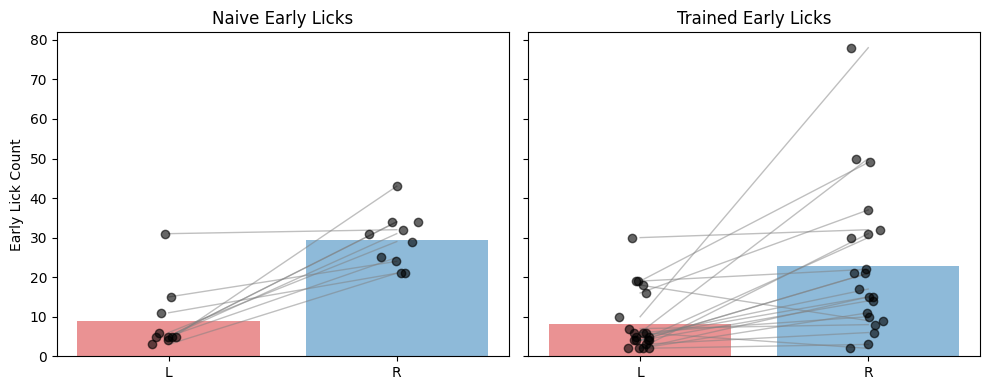

In [247]:

# -- Naive sessions (Left subplot) --
# Flatten all_naive_early_licks_side to an array-of-arrays per session
naive_session_counts = []
for session_licks in all_naive_early_licks_side:
    values, counts = np.unique(session_licks, return_counts=True)
    # Assume 'l' or 'r' only; support sessions missing a side
    count_dict = {'l': 0, 'r': 0}
    for v, c in zip(values, counts):
        count_dict[v] = c
    naive_session_counts.append([count_dict['l'], count_dict['r']])

naive_session_counts = np.array(naive_session_counts)  # shape: (n_sessions, 2)
naive_mean_counts = naive_session_counts.mean(axis=0)

# -- Trained sessions (Right subplot) --
# For trained, don't just count l/r per session, but pair [l, r] per session for consistency
trained_session_counts = []
for session_licks in all_trained_early_licks_side:
    values, counts = np.unique(session_licks, return_counts=True)
    count_dict = {'l': 0, 'r': 0}
    for v, c in zip(values, counts):
        count_dict[v] = c
    # Always keep as [l, r] so lines and dots match
    trained_session_counts.append([count_dict['l'], count_dict['r']])

trained_session_counts = np.array(trained_session_counts)  # shape: (n_sessions, 2)
trained_mean_counts = trained_session_counts.mean(axis=0)

x = np.arange(2)
labels = ['L', 'R']

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)

# --- Plot Naive Sessions ---
ax = axes[0]
bars = ax.bar(x, naive_mean_counts, color=['tab:red', 'tab:blue'], alpha=0.5)

# Connect session points across l and r with thin grey lines
for i in range(naive_session_counts.shape[0]):
    ax.plot(
        x,
        naive_session_counts[i, :],
        c='grey',
        lw=1,
        alpha=0.5,
        zorder=1
    )

# Plot scatter points for each session atop each bar (with jitter, drawn above lines)
for i, side in enumerate(labels):
    ax.scatter(
        np.full(naive_session_counts.shape[0], x[i]) + np.random.normal(0, 0.04, size=naive_session_counts.shape[0]),
        naive_session_counts[:, i],
        color='black',
        alpha=0.6,
        zorder=2
    )

ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylabel('Early Lick Count')
ax.set_title('Naive Early Licks')

# --- Plot Trained Sessions ---
ax = axes[1]
bars = ax.bar(x, trained_mean_counts, color=['tab:red', 'tab:blue'], alpha=0.5)

# Fix: Use the same logic for lines as for scatter points
for i in range(trained_session_counts.shape[0]):
    ax.plot(
        x,
        trained_session_counts[i, :],
        c='grey',
        lw=1,
        alpha=0.5,
        zorder=1
    )

# Fix: Scatter points atop each bar for each session (matching pairing/order)
for i, side in enumerate(labels):
    ax.scatter(
        np.full(trained_session_counts.shape[0], x[i]) + np.random.normal(0, 0.04, size=trained_session_counts.shape[0]),
        trained_session_counts[:, i],
        color='black',
        alpha=0.6,
        zorder=2
    )

ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_title('Trained Early Licks')

plt.tight_layout()
plt.show()

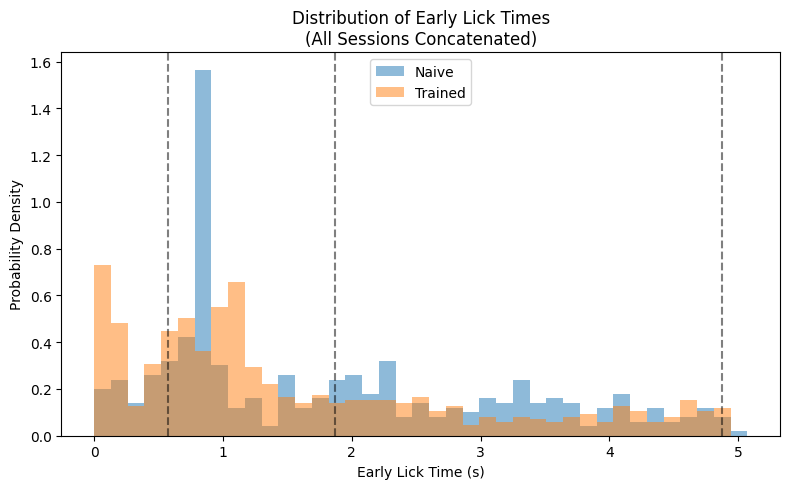

In [246]:
# Plot histogram of early lick times for naive vs trained datasets (concat all sessions)
# Work directly with all_naive_early_licks_time and all_trained_early_licks_time as lists of arrays.

# Concatenate all early lick times for naive and trained into flat 1D arrays for plotting
naive_lick_times = np.concatenate([np.ravel(arr) for arr in all_naive_early_licks_time if arr is not None])
trained_lick_times = np.concatenate([np.ravel(arr) for arr in all_trained_early_licks_time if arr is not None])

# Remove NaN or nonsensical values (if any)
naive_lick_times = naive_lick_times[np.isfinite(naive_lick_times)]
trained_lick_times = trained_lick_times[np.isfinite(trained_lick_times)]

# Make histogram range (e.g. 0 to 1s)
bins = np.linspace(0, 0.57+1.3+3.2, 40)

plt.figure(figsize=(8,5))
plt.hist(naive_lick_times, bins=bins, alpha=0.5, label='Naive', density=True)
plt.hist(trained_lick_times, bins=bins, alpha=0.5, label='Trained', density=True)
plt.axvline(x=0.57, color='k', linestyle='--', alpha=0.5)
plt.axvline(x=1.3+0.57, color='k', linestyle='--', alpha=0.5)
plt.axvline(x=3+1.3+0.57, color='k', linestyle='--', alpha=0.5)
plt.xlabel('Early Lick Time (s)')
plt.ylabel('Probability Density')
plt.title('Distribution of Early Lick Times\n(All Sessions Concatenated)')
plt.legend()
plt.tight_layout()
plt.show()

## Calculate early lick CD using early lick trials (CV folds)

### Naive

In [104]:
naive_paths =[
                r'J:\ephys_data\CW48\python\2024_10_29',
                # r'J:\ephys_data\CW48\python\2024_10_30',
                r'J:\ephys_data\CW48\python\2024_10_31',
                r'J:\ephys_data\CW48\python\2024_11_01',
                # r'J:\ephys_data\CW48\python\2024_11_02',
                r'J:\ephys_data\CW48\python\2024_11_03',
                r'J:\ephys_data\CW48\python\2024_11_04',
                # r'J:\ephys_data\CW48\python\2024_11_05',
                # r'J:\ephys_data\CW48\python\2024_11_06',

                 r'M:\data\CW99\python\2026_05_09',
                  r'M:\data\CW99\python\2026_05_08',

                # r'N:\data\CW100\python\2026_05_19',
                r'N:\data\CW100\python\2026_05_21',
                # r'N:\data\CW100\python\2026_05_22',
                # r'N:\data\CW100\python\2026_05_23',

                # r'G:\ephys_data\CW62\python\2025_06_24',
                r'P:\data\CW104\python\2026_09_30',
                r'P:\data\CW104\python\2026_10_01',
                r'P:\data\CW104\python\2026_10_03',

                r'P:\data\CW103\python\2026_10_01',
                r'P:\data\CW103\python\2026_10_02',
                ]

# naive_paths = [r'P:\data\CW103\python\2026_10_05']


In [105]:
# Calculate early lick CD in naive and trained sessions

path = r'J:\ephys_data\CW48\python\2024_11_01'
# path = r'H:\ephys_data\CW47\python\2024_10_25'
# path = r'G:\ephys_data\CW62\python\2025_06_24'
all_AVproj_allDimR = []
all_AVproj_allDimL = []
lick_count = []
trial_threshold = 3 # same as yang et al
folds = 3
timesteps_before = 10

for path in naive_paths:
    
    if 'CW99' in path or 'CW100' in path or 'CW103' in path:
        s2 = Session(path, side = 'R', filter_low_perf=False, filter_by_stim=False)
    else:
        s2 = Session(path, filter_low_perf=False, filter_by_stim=False) # don't filter out any trials 
    # calculate early lick CD in trained sessions - define here

    early_lick_trials = np.where(s2.early_lick)[0]
    early_lick_side = [i[0] for i in s2.early_lick_side] # use first lick as direction
    early_lick_time = [i[0][0] for i in s2.early_lick_time]

    # for now keep all the early licks (even in ITI)
    stable_set = set.intersection(*(set(s2.stable_trials[n]) for n in s2.good_neurons))
    # drop_idx = [i for i in range(len(early_lick_time)) if (early_lick_time[i] < 0.56 or early_lick_time[i] > 0.62) and early_lick_time[i] > 0.1 and early_lick_trials[i] in stable_set and not s2.stim_ON[early_lick_trials[i]]]
    drop_idx = [i for i in range(len(early_lick_time)) if early_lick_time[i] > 0.1 and early_lick_time[i] < 2.5 and early_lick_trials[i] in stable_set and not s2.stim_ON[early_lick_trials[i]]]

    early_lick_trials = np.array(early_lick_trials)[drop_idx]
    early_lick_side = np.array(early_lick_side)[drop_idx]
    early_lick_time = np.array(early_lick_time)[drop_idx]


    # project early lick CD
    r_trials = early_lick_trials[np.where(early_lick_side == 'r')[0]]
    l_trials = early_lick_trials[np.where(early_lick_side == 'l')[0]]

    r_trial_lick = early_lick_time[np.where(early_lick_side == 'r')[0]]
    l_trial_lick = early_lick_time[np.where(early_lick_side == 'l')[0]]
    # Get the frame where the early lick happened, per trial

    if len(r_trial_lick) < trial_threshold or len(l_trial_lick) < trial_threshold:
        print('Not enough trials to train: R = {}, L = {} in {}'.format(len(r_trial_lick), len(l_trial_lick), path))
        continue

    lick_count += [(len(r_trial_lick), len(l_trial_lick), path)]

    # Align every trial to shortest early lick (new go cue time)
    r_cue, l_cue = min(r_trial_lick), min(l_trial_lick)
    r_end, l_end = max(r_trial_lick), max(l_trial_lick)

    # get the train vs test indices - do CV and average across folds
    all_proj_allDimR = []
    all_proj_allDimL = []
    all_r_idx, all_l_idx = np.arange(len(r_trials)), np.arange(len(l_trials))
    np.random.seed(0)  # Set a seed for replicable randomness

    rtmp = np.random.permutation(len(all_r_idx))
    ltmp = np.random.permutation(len(all_l_idx))
    s2.binsize = 250
    s2.timestep = 50



    for i in range(folds): # each cv fold

        # Calculate fold boundaries for 4-fold cross-validation for both rtmp and ltmp
        fold_size_r = int(np.floor(len(rtmp) / folds))
        fold_size_l = int(np.floor(len(ltmp) / folds))

        # Get i-th test and train indices for R
        test_start_r = i * fold_size_r
        test_end_r = min((i + 1) * fold_size_r, len(rtmp))
        test_r_idx = rtmp[test_start_r:test_end_r]
        train_r_idx = np.concatenate((rtmp[:test_start_r], rtmp[test_end_r:]))

        # Get i-th test and train indices for L
        test_start_l = i * fold_size_l
        test_end_l = min((i + 1) * fold_size_l, len(ltmp))
        test_l_idx = ltmp[test_start_l:test_end_l]
        train_l_idx = np.concatenate((ltmp[:test_start_l], ltmp[test_end_l:]))

        # compile train vs test psths
        PSTH_yes_correct, PSTH_no_correct = [], []
        PSTH_yes_correct_test, PSTH_no_correct_test = [], []
        PSTH_yes_correct_test_mean, PSTH_no_correct_test_mean = [], []

        # Ephys code
        # go per trial in the train set to new 'go' cue
        r_train = []
        for idx in train_r_idx:
            tmp, time, _ = s2.get_PSTH_multiple(s2.good_neurons, r_trials[idx], binsize=s2.binsize, timestep = s2.timestep)
            lickidx = np.where(time >  r_trial_lick[idx])[0][0] # get timepoint of early lick time for this trial

            x = tmp[:, lickidx - timesteps_before:lickidx]
            r_train.append(np.mean(x, axis=1))
                
                
        l_train = []
        for idx in train_l_idx:
            tmp, time, _ = s2.get_PSTH_multiple(s2.good_neurons, l_trials[idx], binsize=s2.binsize, timestep = s2.timestep)
            lickidx = np.where(time > l_trial_lick[idx])[0][0]
            x = tmp[:, lickidx - timesteps_before:lickidx]
            l_train.append(np.mean(x, axis=1))

        CD_early_lick = np.nanmean(r_train, axis=0) - np.nanmean(l_train, axis=0)



        proj_allDimR = []
        for idx in test_r_idx:
            tmp, time, _ = s2.get_PSTH_multiple(s2.good_neurons, r_trials[idx], binsize=s2.binsize, timestep = s2.timestep)
            lickidx = np.where(time > r_trial_lick[idx])[0][0]
            
            tmp = tmp[:, :lickidx]
            proj_allDim = np.dot(tmp.T, CD_early_lick)
            proj_allDimR += [proj_allDim]
            
        proj_allDimL = []
        for idx in test_l_idx:
            tmp, time, _ = s2.get_PSTH_multiple(s2.good_neurons, l_trials[idx], binsize=s2.binsize, timestep = s2.timestep)
            lickidx = np.where(time > l_trial_lick[idx])[0][0]

            tmp = tmp[:, :lickidx]
            proj_allDim = np.dot(tmp.T, CD_early_lick)
            proj_allDimL += [proj_allDim]

        # Make all inner lists of proj_allDimL end-aligned before averaging
        min_len = min(len(lst) for lst in proj_allDimL)
        aligned_proj_allDimL = [lst[-min_len:] for lst in proj_allDimL]
        averaged_proj_allDimL = np.mean(aligned_proj_allDimL, axis=0)
 
        min_len = min(len(lst) for lst in proj_allDimR)
        aligned_proj_allDimR = [lst[-min_len:] for lst in proj_allDimR]
        averaged_proj_allDimR = np.mean(aligned_proj_allDimR, axis=0)


        all_proj_allDimR += [averaged_proj_allDimR]
        all_proj_allDimL += [averaged_proj_allDimL]
    

    min_len = min(len(lst) for lst in all_proj_allDimR)
    all_aligned_proj_allDimR = [lst[-min_len:] for lst in all_proj_allDimR]
    AVproj_allDimR = np.mean(all_aligned_proj_allDimR, axis=0)
    
    min_len = min(len(lst) for lst in all_proj_allDimL)
    all_aligned_proj_allDimL = [lst[-min_len:] for lst in all_proj_allDimL]
    AVproj_allDimL = np.mean(all_aligned_proj_allDimL, axis=0)

    all_AVproj_allDimR += [AVproj_allDimR]
    all_AVproj_allDimL += [AVproj_allDimL]








18 trials removed for stability reasons
only ppyr neurons: 333 --> 299
Not enough trials to train: R = 6, L = 1 in J:\ephys_data\CW48\python\2024_10_29
16 trials removed for stability reasons
only ppyr neurons: 299 --> 249
Not enough trials to train: R = 23, L = 1 in J:\ephys_data\CW48\python\2024_10_31
11 trials removed for stability reasons
only ppyr neurons: 225 --> 184
Not enough trials to train: R = 11, L = 1 in J:\ephys_data\CW48\python\2024_11_01
84 trials removed for stability reasons
only ppyr neurons: 268 --> 227
Not enough trials to train: R = 16, L = 0 in J:\ephys_data\CW48\python\2024_11_03
26 trials removed for stability reasons
only ppyr neurons: 241 --> 210
Not enough trials to train: R = 17, L = 0 in J:\ephys_data\CW48\python\2024_11_04
1 trials removed for stability reasons
only ppyr neurons: 131 --> 120
12 trials removed for stability reasons
only ppyr neurons: 250 --> 210
2 trials removed for stability reasons
only ppyr neurons: 145 --> 127
41 trials removed for sta

In [106]:
lick_count 

[(10, 3, 'M:\\data\\CW99\\python\\2026_05_09'),
 (9, 16, 'M:\\data\\CW99\\python\\2026_05_08'),
 (22, 13, 'N:\\data\\CW100\\python\\2026_05_21'),
 (156, 105, 'P:\\data\\CW104\\python\\2026_09_30'),
 (101, 143, 'P:\\data\\CW104\\python\\2026_10_01'),
 (104, 101, 'P:\\data\\CW104\\python\\2026_10_03'),
 (26, 73, 'P:\\data\\CW103\\python\\2026_10_01'),
 (18, 44, 'P:\\data\\CW103\\python\\2026_10_02')]

In [107]:
all_norm_avproj_allDimR = [z_score_normalize(i) for i in all_AVproj_allDimR[:]]
all_norm_avproj_allDimL = [z_score_normalize(i) for i in all_AVproj_allDimL[:]]

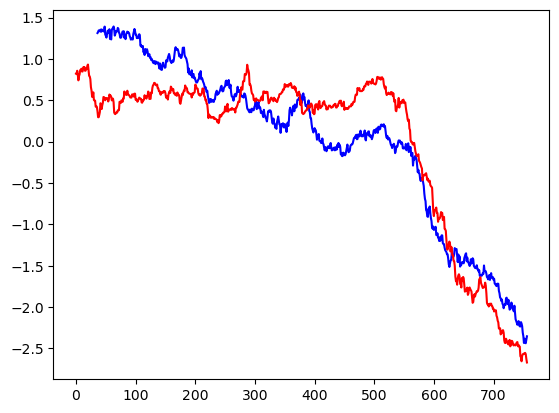

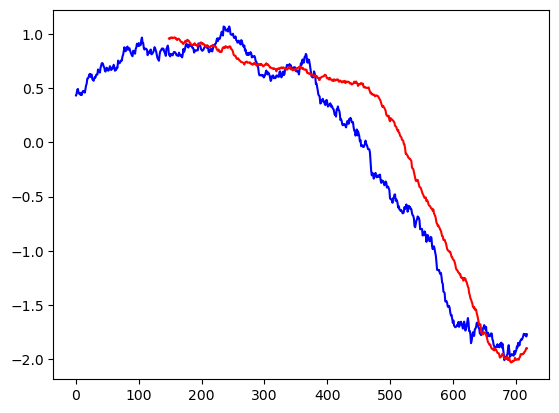

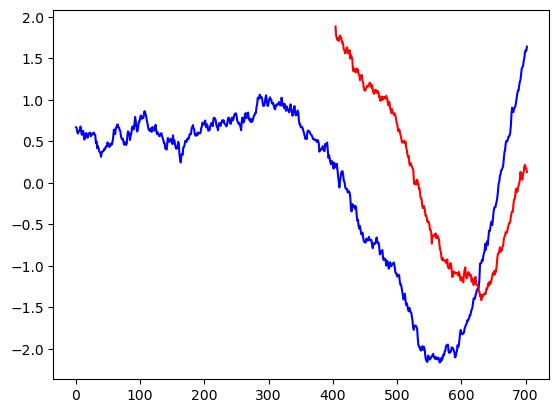

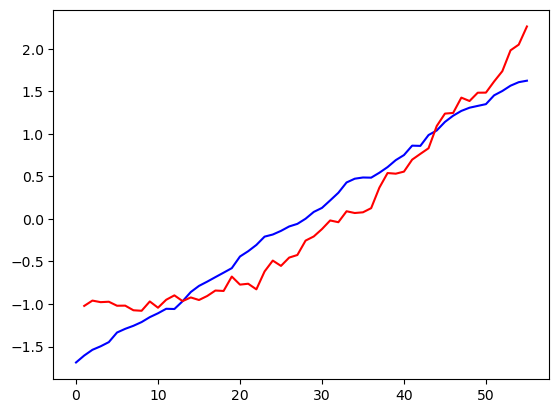

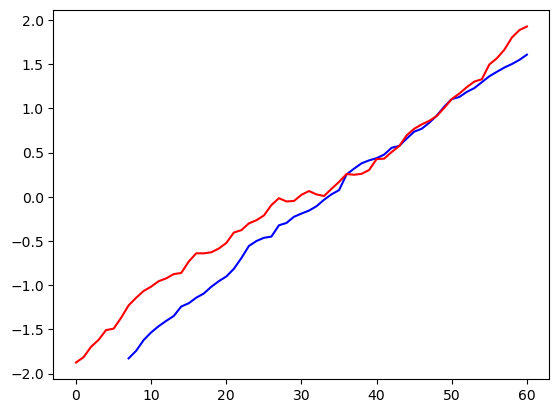

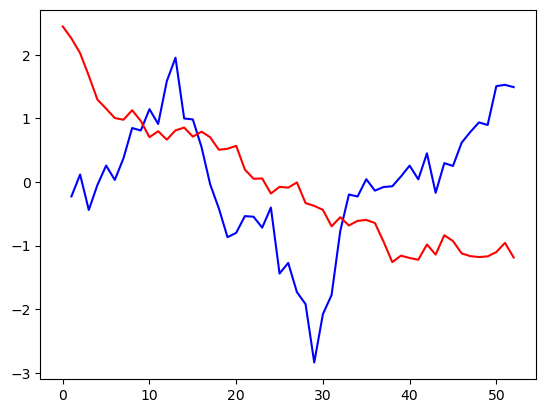

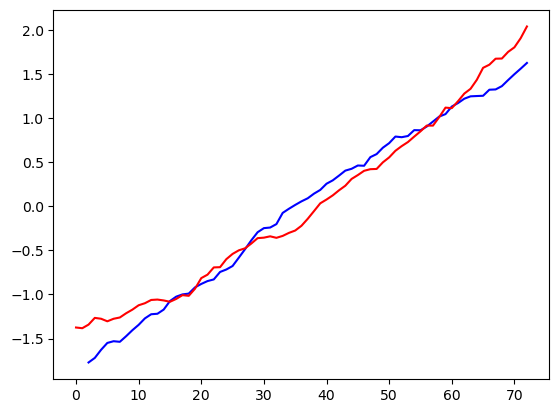

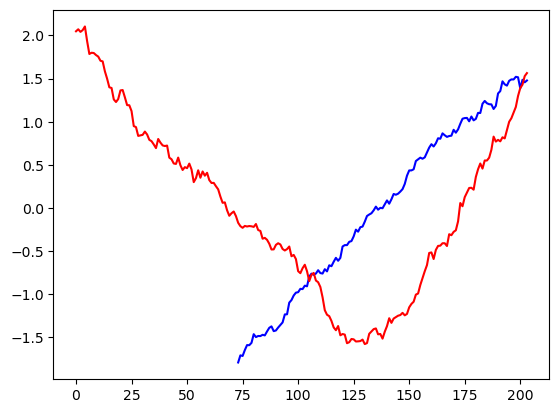

In [108]:
for i in range(len(all_norm_avproj_allDimR)):
    # Plot so the ends are aligned (right-justified), padding with NaN on the left.
    r = all_norm_avproj_allDimR[i]
    l = all_norm_avproj_allDimL[i]
    max_len = max(len(r), len(l))
    r_padded = np.full(max_len, np.nan)
    l_padded = np.full(max_len, np.nan)
    r_padded[-len(r):] = r
    l_padded[-len(l):] = l
    plt.plot(r_padded, color="b")
    plt.plot(l_padded, color="r")
    plt.show()

### Naive plot

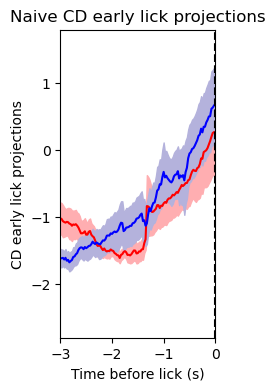

In [118]:

num_steps = 200

# For right projections
right_padded = []
for arr in all_norm_avproj_allDimR:
    if len(arr) >= num_steps:
        right_segment = arr[-num_steps:]
    else:
        pad = np.full(num_steps - len(arr), np.nan)
        right_segment = np.concatenate([pad, arr])
    right_padded.append(right_segment)
right_padded = np.vstack(right_padded)

# For left projections
left_padded = []
for arr in all_norm_avproj_allDimL:
    if len(arr) >= num_steps:
        left_segment = arr[-num_steps:]
    else:
        pad = np.full(num_steps - len(arr), np.nan)
        left_segment = np.concatenate([pad, arr])
    left_padded.append(left_segment)
left_padded = np.vstack(left_padded)

# Compute mean and std, ignoring nan at starts
all_avg_left = np.nanmean(left_padded, axis=0)
all_avg_right = np.nanmean(right_padded, axis=0)

# Standard error, ignoring nan (use np.nanstd and N as count of non-nan at each time-point)
all_std_left = np.nanstd(left_padded, axis=0) / np.sqrt(np.sum(~np.isnan(left_padded), axis=0))
all_std_right = np.nanstd(right_padded, axis=0) / np.sqrt(np.sum(~np.isnan(right_padded), axis=0))

time_plot = np.arange(-num_steps * 0.025, 0, 0.025)

# center on zero after -3 secs
# idx_end = np.where(time_plot >= -3)[0]
# all_avg_left -= np.mean((all_avg_left[idx_end], all_avg_right[idx_end]))  # last 20 time points
# all_avg_right -= np.mean((all_avg_left[idx_end], all_avg_right[idx_end]))  # last 20 time points

f = plt.figure(figsize=(2, 4))

plt.plot(time_plot, all_avg_left, c='r')
plt.plot(time_plot, all_avg_right, c='b')

# plt.fill_between(time_plot, np.mean(all_avg_left, axis=0) - np.std(all_avg_left, axis=0), 
#         np.mean(all_avg_left, axis=0) + np.std(all_avg_left, axis=0),
#         color=['#ffaeb1'])
# plt.fill_between(time_plot, np.mean(all_avg_right, axis=0) - np.std(all_avg_right, axis=0), 
#         np.mean(all_avg_right, axis=0) + np.std(all_avg_right, axis=0),
#         color=['#b4b2dc'])
plt.fill_between(time_plot, all_avg_left - all_std_left, 
        all_avg_left + all_std_left,
        color=['#ffaeb1'])
plt.fill_between(time_plot, all_avg_right - all_std_right, 
        all_avg_right + all_std_right,
        color=['#b4b2dc'])
plt.axvline(x=0, color='k', linestyle='--')
plt.xlim(-3, 0)
plt.ylim(-2.8, 1.8)
plt.xlabel('Time before lick (s)')
plt.ylabel('CD early lick projections')
plt.title('Naive CD early lick projections')
# plt.savefig(r'P:\paperfigures\fig1\naive_CD_early_lick_projections_all.pdf')
plt.show()





In [115]:
time_plot

array([-5.   , -4.975, -4.95 , -4.925, -4.9  , -4.875, -4.85 , -4.825,
       -4.8  , -4.775, -4.75 , -4.725, -4.7  , -4.675, -4.65 , -4.625,
       -4.6  , -4.575, -4.55 , -4.525, -4.5  , -4.475, -4.45 , -4.425,
       -4.4  , -4.375, -4.35 , -4.325, -4.3  , -4.275, -4.25 , -4.225,
       -4.2  , -4.175, -4.15 , -4.125, -4.1  , -4.075, -4.05 , -4.025,
       -4.   , -3.975, -3.95 , -3.925, -3.9  , -3.875, -3.85 , -3.825,
       -3.8  , -3.775, -3.75 , -3.725, -3.7  , -3.675, -3.65 , -3.625,
       -3.6  , -3.575, -3.55 , -3.525, -3.5  , -3.475, -3.45 , -3.425,
       -3.4  , -3.375, -3.35 , -3.325, -3.3  , -3.275, -3.25 , -3.225,
       -3.2  , -3.175, -3.15 , -3.125, -3.1  , -3.075, -3.05 , -3.025,
       -3.   , -2.975, -2.95 , -2.925, -2.9  , -2.875, -2.85 , -2.825,
       -2.8  , -2.775, -2.75 , -2.725, -2.7  , -2.675, -2.65 , -2.625,
       -2.6  , -2.575, -2.55 , -2.525, -2.5  , -2.475, -2.45 , -2.425,
       -2.4  , -2.375, -2.35 , -2.325, -2.3  , -2.275, -2.25 , -2.225,
      

### Trained

In [355]:
# Calculate early lick CD in naive and trained sessions

path = r'J:\ephys_data\CW48\python\2024_11_01'
# path = r'H:\ephys_data\CW47\python\2024_10_25'
# path = r'G:\ephys_data\CW62\python\2025_06_24'
all_AVproj_allDimR = []
all_AVproj_allDimL = []

all_lick_counts = []
trial_threshold = 3 # same as yang et al
folds = 3
timesteps_before = 10

for path in cat(trained_paths_high_performance):
# for path in cat(trained_paths):
        
    s2 = Session(path, filter_low_perf=False, filter_by_stim=False) # don't filter out any trials 
    # calculate early lick CD in trained sessions - define here

    early_lick_trials = np.where(s2.early_lick)[0]
    early_lick_side = [i[0] for i in s2.early_lick_side] # use first lick as direction
    early_lick_time = [i[0][0] for i in s2.early_lick_time]

    # for now keep all the early licks (even in ITI)
    stable_set = set.intersection(*(set(s2.stable_trials[n]) for n in s2.good_neurons))
    # drop_idx = [i for i in range(len(early_lick_time)) if (early_lick_time[i] < 0.56 or early_lick_time[i] > 0.62) and early_lick_time[i] > 0.1 and early_lick_trials[i] in stable_set and not s2.stim_ON[early_lick_trials[i]]]
    drop_idx = [i for i in range(len(early_lick_time)) if early_lick_time[i] > 0.1 and early_lick_time[i] < 2.5 and early_lick_trials[i] in stable_set and not s2.stim_ON[early_lick_trials[i]]]
    early_lick_trials = np.array(early_lick_trials)[drop_idx]
    early_lick_side = np.array(early_lick_side)[drop_idx]
    early_lick_time = np.array(early_lick_time)[drop_idx]


    # project early lick CD
    r_trials = early_lick_trials[np.where(early_lick_side == 'r')[0]]
    l_trials = early_lick_trials[np.where(early_lick_side == 'l')[0]]

    r_trial_lick = early_lick_time[np.where(early_lick_side == 'r')[0]]
    l_trial_lick = early_lick_time[np.where(early_lick_side == 'l')[0]]
    # Get the frame where the early lick happened, per trial

    if len(r_trial_lick) < trial_threshold or len(l_trial_lick) < trial_threshold:
        print('Not enough trials to train')
        continue

    # Align every trial to shortest early lick (new go cue time)
    r_cue, l_cue = min(r_trial_lick), min(l_trial_lick)
    r_end, l_end = max(r_trial_lick), max(l_trial_lick)

    # get the train vs test indices - do CV and average across folds
    all_proj_allDimR = []
    all_proj_allDimL = []
    all_r_idx, all_l_idx = np.arange(len(r_trials)), np.arange(len(l_trials))
    np.random.seed(42)  # Set a seed for replicable randomness
    np.random.seed(0)  # Set a seed for replicable randomness
    rtmp = np.random.permutation(len(all_r_idx))
    ltmp = np.random.permutation(len(all_l_idx))
    s2.binsize = 250
    s2.timestep = 50

    all_lick_counts += [(len(r_trial_lick), len(l_trial_lick), path)]

    for i in range(folds): # each cv fold

        # Calculate fold boundaries for 4-fold cross-validation for both rtmp and ltmp
        fold_size_r = int(np.floor(len(rtmp) / folds))
        fold_size_l = int(np.floor(len(ltmp) / folds))

        # Get i-th test and train indices for R
        test_start_r = i * fold_size_r
        test_end_r = min((i + 1) * fold_size_r, len(rtmp))
        test_r_idx = rtmp[test_start_r:test_end_r]
        train_r_idx = np.concatenate((rtmp[:test_start_r], rtmp[test_end_r:]))

        # Get i-th test and train indices for L
        test_start_l = i * fold_size_l
        test_end_l = min((i + 1) * fold_size_l, len(ltmp))
        test_l_idx = ltmp[test_start_l:test_end_l]
        train_l_idx = np.concatenate((ltmp[:test_start_l], ltmp[test_end_l:]))

        # compile train vs test psths
        PSTH_yes_correct, PSTH_no_correct = [], []
        PSTH_yes_correct_test, PSTH_no_correct_test = [], []
        PSTH_yes_correct_test_mean, PSTH_no_correct_test_mean = [], []

        # Ephys code
        # go per trial in the train set to new 'go' cue
        r_train = []
        for idx in train_r_idx:
            tmp, time, _ = s2.get_PSTH_multiple(s2.good_neurons, r_trials[idx], binsize=s2.binsize, timestep = s2.timestep)
            lickidx = np.where(time >  r_trial_lick[idx])[0][0] # get timepoint of early lick time for this trial

            x = tmp[:, lickidx - timesteps_before:lickidx]
            r_train.append(np.mean(x, axis=1))
                
                
        l_train = []
        for idx in train_l_idx:
            tmp, time, _ = s2.get_PSTH_multiple(s2.good_neurons, l_trials[idx], binsize=s2.binsize, timestep = s2.timestep)
            lickidx = np.where(time > l_trial_lick[idx])[0][0]
            x = tmp[:, lickidx - timesteps_before:lickidx]
            l_train.append(np.mean(x, axis=1))

        CD_early_lick = np.nanmean(r_train, axis=0) - np.nanmean(l_train, axis=0)

        proj_allDimR = []
        for idx in test_r_idx:
            tmp, time, _ = s2.get_PSTH_multiple(s2.good_neurons, r_trials[idx], binsize=s2.binsize, timestep = s2.timestep)
            lickidx = np.where(time > r_trial_lick[idx])[0][0]

            tmp = tmp[:, :lickidx]
            proj_allDim = np.dot(tmp.T, CD_early_lick)
            proj_allDimR += [proj_allDim]
            
        proj_allDimL = []
        for idx in test_l_idx:
            tmp, time, _ = s2.get_PSTH_multiple(s2.good_neurons, l_trials[idx], binsize=s2.binsize, timestep = s2.timestep)
            lickidx = np.where(time > l_trial_lick[idx])[0][0]

            tmp = tmp[:, :lickidx]
            proj_allDim = np.dot(tmp.T, CD_early_lick)
            proj_allDimL += [proj_allDim]

        # Make all inner lists of proj_allDimL end-aligned before averaging
        min_len = min(len(lst) for lst in proj_allDimL)
        aligned_proj_allDimL = [lst[-min_len:] for lst in proj_allDimL]
        averaged_proj_allDimL = np.mean(aligned_proj_allDimL, axis=0)
 
        min_len = min(len(lst) for lst in proj_allDimR)
        aligned_proj_allDimR = [lst[-min_len:] for lst in proj_allDimR]
        averaged_proj_allDimR = np.mean(aligned_proj_allDimR, axis=0)


        all_proj_allDimR += [averaged_proj_allDimR]
        all_proj_allDimL += [averaged_proj_allDimL]
    

    min_len = min(len(lst) for lst in all_proj_allDimR)
    all_aligned_proj_allDimR = [lst[-min_len:] for lst in all_proj_allDimR]
    AVproj_allDimR = np.mean(all_aligned_proj_allDimR, axis=0)
    
    min_len = min(len(lst) for lst in all_proj_allDimL)
    all_aligned_proj_allDimL = [lst[-min_len:] for lst in all_proj_allDimL]
    AVproj_allDimL = np.mean(all_aligned_proj_allDimL, axis=0)

    all_AVproj_allDimR += [AVproj_allDimR]
    all_AVproj_allDimL += [AVproj_allDimL]








Loading good trial inds from file
7 trials removed for stability reasons
only ppyr neurons: 305 --> 271
Not enough trials to train
Loading good trial inds from file
0 trials removed for stability reasons
only ppyr neurons: 422 --> 377
Not enough trials to train
Loading good trial inds from file
20 trials removed for stability reasons
only ppyr neurons: 328 --> 291
Loading good trial inds from file
15 trials removed for stability reasons
only ppyr neurons: 178 --> 154
Loading good trial inds from file
22 trials removed for stability reasons
only ppyr neurons: 232 --> 203
Loading good trial inds from file
33 trials removed for stability reasons
only ppyr neurons: 194 --> 184
Not enough trials to train
Loading good trial inds from file
0 trials removed for stability reasons
only ppyr neurons: 407 --> 363
Loading good trial inds from file
0 trials removed for stability reasons
only ppyr neurons: 349 --> 298
Loading good trial inds from file
4 trials removed for stability reasons
only ppyr 

In [356]:
all_lick_counts, test_r_idx, train_r_idx

([(20, 3, 'L:\\data\\CW68\\python\\2025_12_13'),
  (21, 5, 'L:\\data\\CW68\\python\\2025_12_15'),
  (5, 3, 'L:\\data\\CW70\\python\\2025_11_02'),
  (8, 11, 'G:\\ephys_data\\CW65\\python\\2025_02_25'),
  (5, 3, 'H:\\ephys_data\\CW47\\python\\2024_10_25')],
 array([1]),
 array([2, 0, 3, 4]))

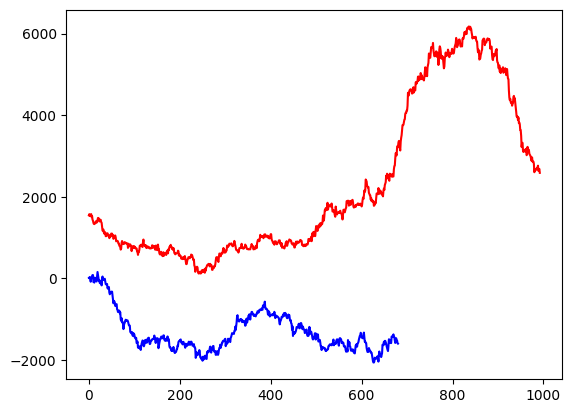

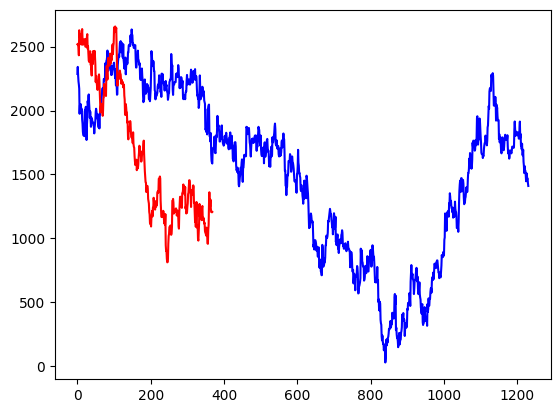

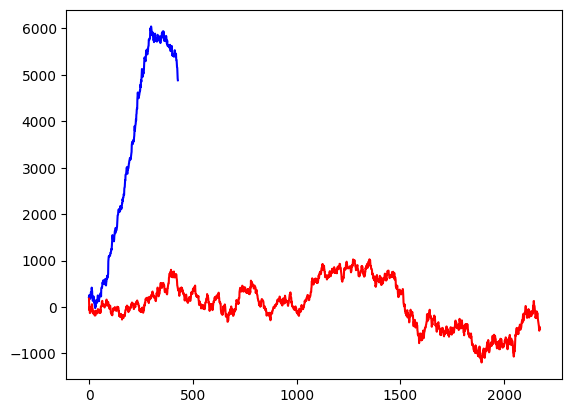

In [357]:
for i in range(len(all_proj_allDimR)):
    plt.plot(all_proj_allDimR[i], color = 'b')
    plt.plot(all_proj_allDimL[i], color = 'r')
    plt.show()

In [358]:
all_norm_avproj_allDimR = [z_score_normalize(i) for i in all_AVproj_allDimR[2:]]
all_norm_avproj_allDimL = [z_score_normalize(i) for i in all_AVproj_allDimL[2:]]

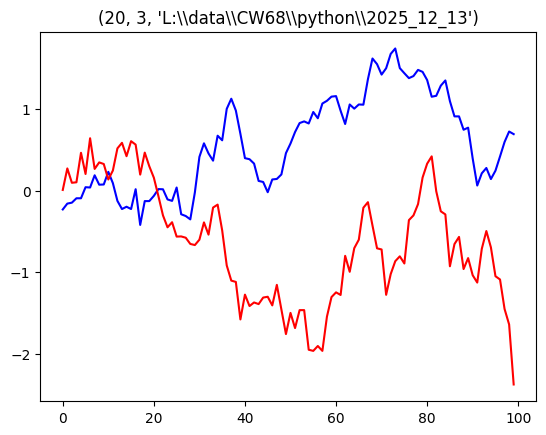

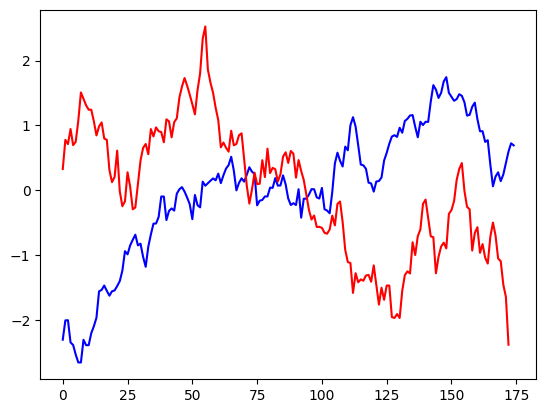

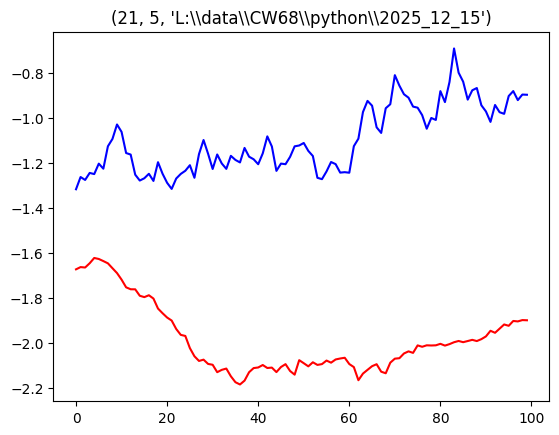

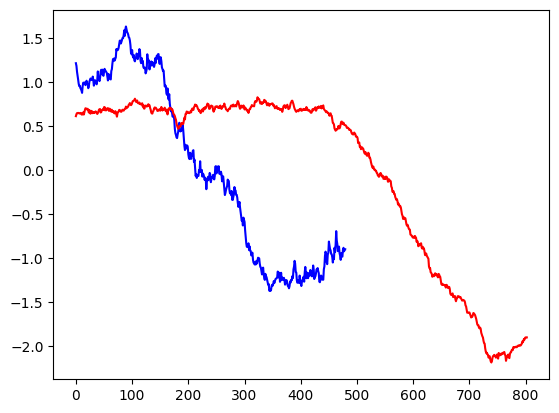

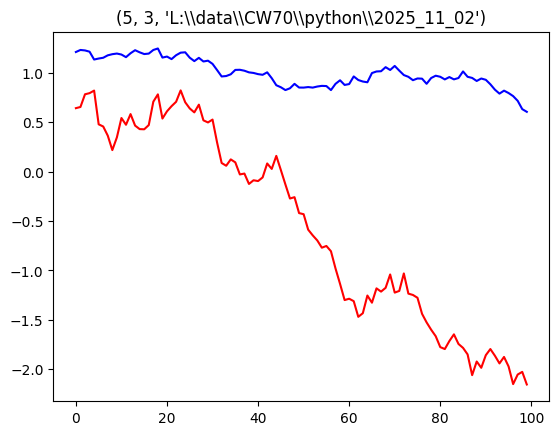

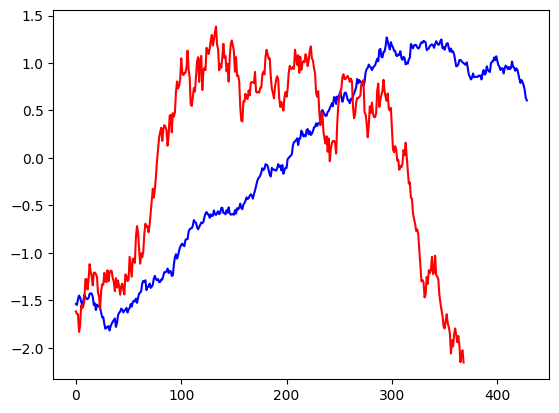

In [359]:

min_len_r = min(len(lst) for lst in all_norm_avproj_allDimR)
# all_aligned_proj_allDimR = [lst[-min_len:] for lst in all_proj_allDimR]
# AVproj_allDimR = np.mean(all_aligned_proj_allDimR, axis=0)

min_len_l = min(len(lst) for lst in all_norm_avproj_allDimL)
# all_aligned_proj_allDimR = [lst[-min_len:] for lst in all_proj_allDimR]
# AVproj_allDimR = np.mean(all_aligned_proj_allDimR, axis=0)

min_len_all = min(min_len_r, min_len_l)
num_steps = 100

for i in range(len(all_norm_avproj_allDimR)):
    # Pad right trial with nan if < num_steps, otherwise just take last num_steps
    right = all_norm_avproj_allDimR[i]
    if len(right) >= num_steps:
        right_segment = right[-num_steps:]
    else:
        pad = np.full(num_steps - len(right), np.nan)
        right_segment = np.concatenate([pad, right])

    # Pad left trial with nan if < num_steps, otherwise just take last num_steps
    left = all_norm_avproj_allDimL[i]
    if len(left) >= num_steps:
        left_segment = left[-num_steps:]
    else:
        pad = np.full(num_steps - len(left), np.nan)
        left_segment = np.concatenate([pad, left])

    plt.plot(right_segment, color='b')
    plt.plot(left_segment, color='r')
    plt.title(all_lick_counts[:][i])
    plt.show()

    # Optionally: plot the originals (not padded)
    plt.plot(all_norm_avproj_allDimR[i], color='b')
    plt.plot(all_norm_avproj_allDimL[i], color='r')
    plt.show()

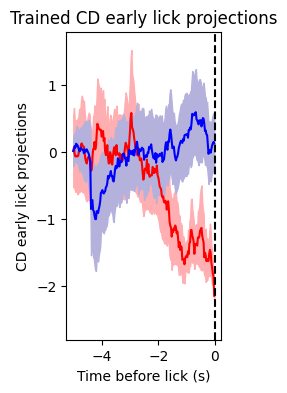

In [360]:
# min_r_len = min([len(i) for i in all_norm_avproj_allDimR])
# min_l_len = min([len(i) for i in all_norm_avproj_allDimL])

num_steps = 200

# For right projections
right_padded = []
for arr in all_norm_avproj_allDimR:
    if len(arr) >= num_steps:
        right_segment = arr[-num_steps:]
    else:
        pad = np.full(num_steps - len(arr), np.nan)
        right_segment = np.concatenate([pad, arr])
    right_padded.append(right_segment)
right_padded = np.vstack(right_padded)

# For left projections
left_padded = []
for arr in all_norm_avproj_allDimL:
    if len(arr) >= num_steps:
        left_segment = arr[-num_steps:]
    else:
        pad = np.full(num_steps - len(arr), np.nan)
        left_segment = np.concatenate([pad, arr])
    left_padded.append(left_segment)
left_padded = np.vstack(left_padded)

# Compute mean and std, ignoring nan at starts
all_avg_left = np.nanmean(left_padded, axis=0)
all_avg_right = np.nanmean(right_padded, axis=0)

# Standard error, ignoring nan (use np.nanstd and N as count of non-nan at each time-point)
all_std_left = np.nanstd(left_padded, axis=0) / np.sqrt(np.sum(~np.isnan(left_padded), axis=0))
all_std_right = np.nanstd(right_padded, axis=0) / np.sqrt(np.sum(~np.isnan(right_padded), axis=0))

time_plot = np.arange(-num_steps * 0.025, 0, 0.025)

f = plt.figure(figsize=(2, 4))

plt.plot(time_plot, all_avg_left, c='r')
plt.plot(time_plot, all_avg_right, c='b')

# plt.fill_between(time_plot, np.mean(all_avg_left, axis=0) - np.std(all_avg_left, axis=0), 
#         np.mean(all_avg_left, axis=0) + np.std(all_avg_left, axis=0),
#         color=['#ffaeb1'])
# plt.fill_between(time_plot, np.mean(all_avg_right, axis=0) - np.std(all_avg_right, axis=0), 
#         np.mean(all_avg_right, axis=0) + np.std(all_avg_right, axis=0),
#         color=['#b4b2dc'])
plt.fill_between(time_plot, all_avg_left - all_std_left, 
        all_avg_left + all_std_left,
        color=['#ffaeb1'])
plt.fill_between(time_plot, all_avg_right - all_std_right, 
        all_avg_right + all_std_right,
        color=['#b4b2dc'])
plt.axvline(x=0, color='k', linestyle='--')
plt.ylim(-2.8, 1.8)
plt.xlabel('Time before lick (s)')
plt.ylabel('CD early lick projections')
plt.title('Trained CD early lick projections')
# plt.savefig(r'P:\paperfigures\fig1\trained_CD_early_lick_projections.pdf')
plt.show()



## Trained and naive mice early lick using choice CD

18 trials removed for stability reasons
only ppyr neurons: 333 --> 299
in house train test sorting
time taken: 64.15619421005249


c:\Users\catherinewang\AppData\Local\Programs\Python\Python38\lib\site-packages\numpy\core\fromnumeric.py:3464: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\catherinewang\AppData\Local\Programs\Python\Python38\lib\site-packages\numpy\core\_methods.py:184: RuntimeWarning: invalid value encountered in divide
  ret = um.true_divide(


calculation time: 0.3796374797821045


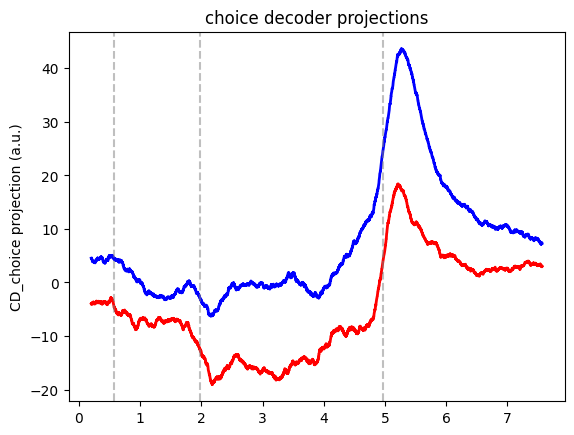

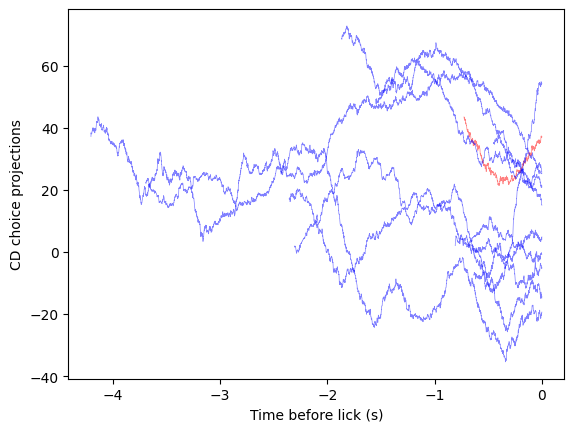

c:\Users\catherinewang\AppData\Local\Programs\Python\Python38\lib\site-packages\numpy\core\_methods.py:192: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
c:\Users\catherinewang\AppData\Local\Programs\Python\Python38\lib\site-packages\numpy\core\_methods.py:269: RuntimeWarning: Degrees of freedom <= 0 for slice
  ret = _var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
c:\Users\catherinewang\AppData\Local\Programs\Python\Python38\lib\site-packages\numpy\core\_methods.py:226: RuntimeWarning: invalid value encountered in divide
  arrmean = um.true_divide(arrmean, div, out=arrmean,
c:\Users\catherinewang\AppData\Local\Programs\Python\Python38\lib\site-packages\numpy\core\_methods.py:261: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


16 trials removed for stability reasons
only ppyr neurons: 299 --> 249
in house train test sorting
time taken: 44.77229642868042
calculation time: 0.30774450302124023


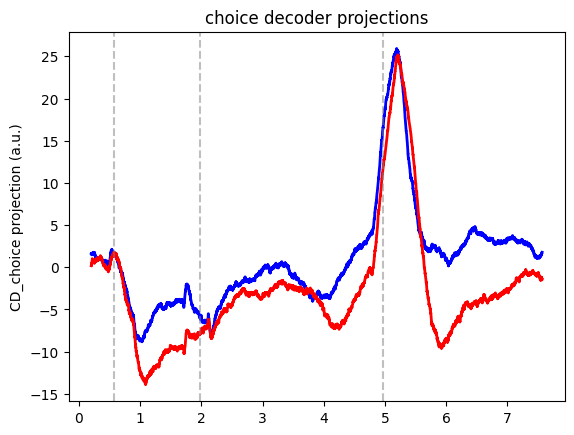

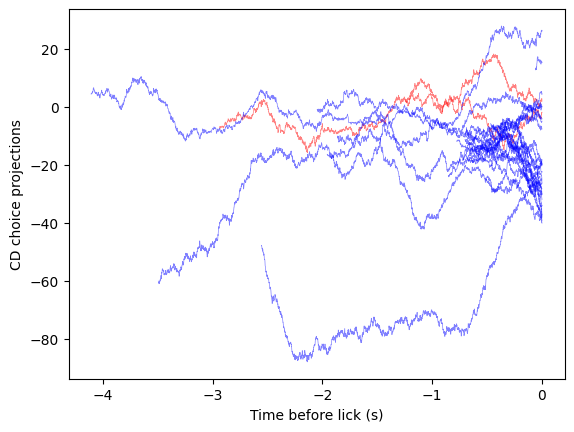

11 trials removed for stability reasons
only ppyr neurons: 225 --> 184
in house train test sorting
time taken: 29.43783974647522
calculation time: 0.22844982147216797


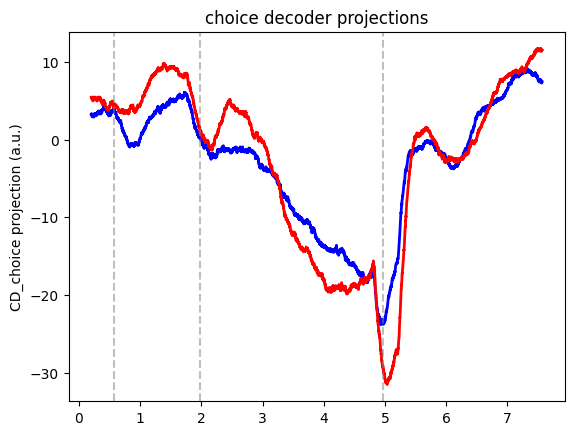

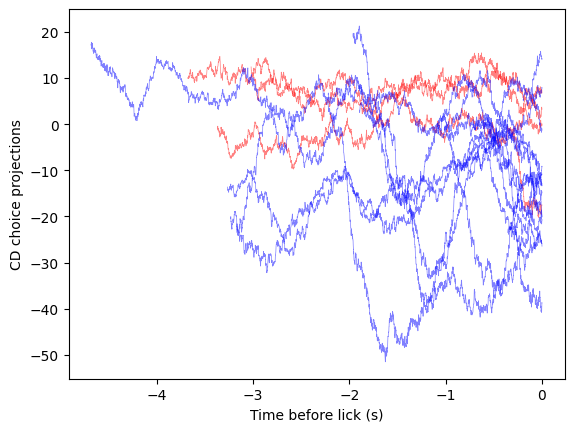

28 trials removed for stability reasons
only ppyr neurons: 270 --> 242
in house train test sorting
time taken: 43.28794622421265
calculation time: 0.29956483840942383


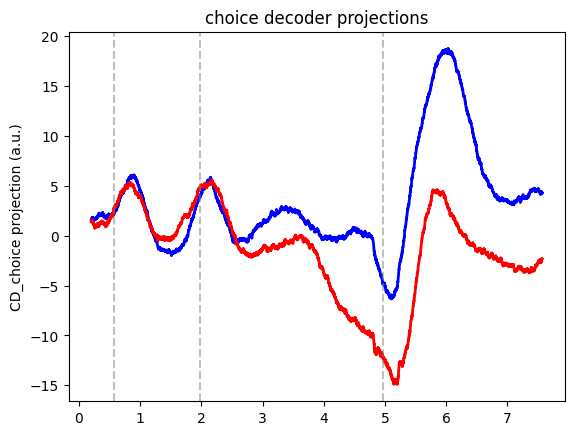

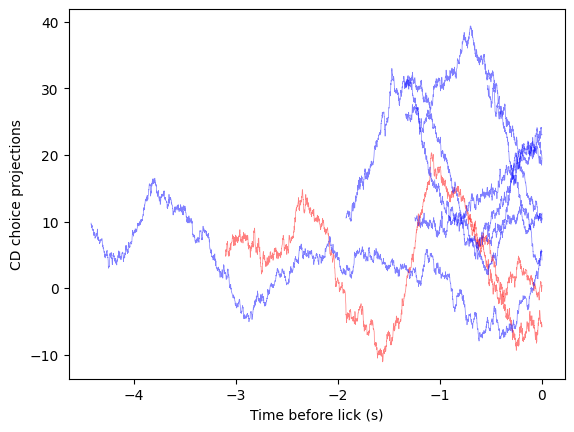

84 trials removed for stability reasons
only ppyr neurons: 268 --> 227
in house train test sorting
time taken: 30.181326866149902
calculation time: 0.2761838436126709


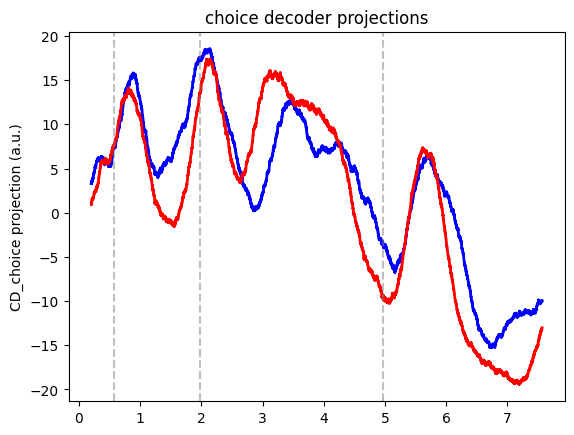

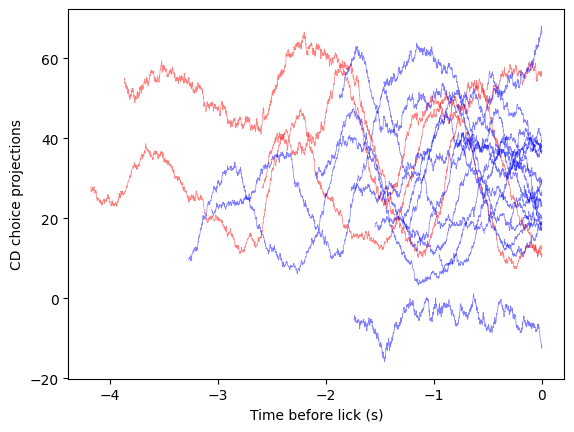

26 trials removed for stability reasons
only ppyr neurons: 241 --> 210
in house train test sorting
time taken: 30.243741273880005
calculation time: 0.2638685703277588


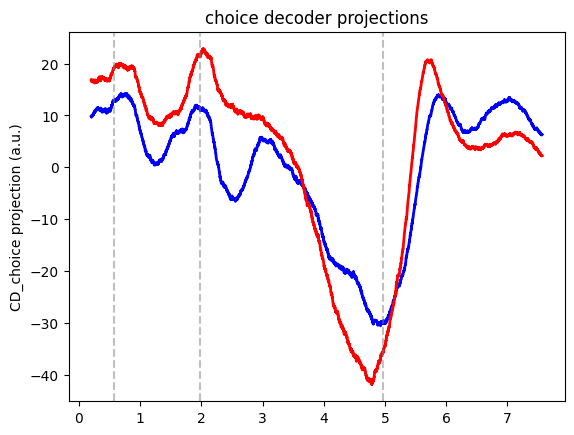

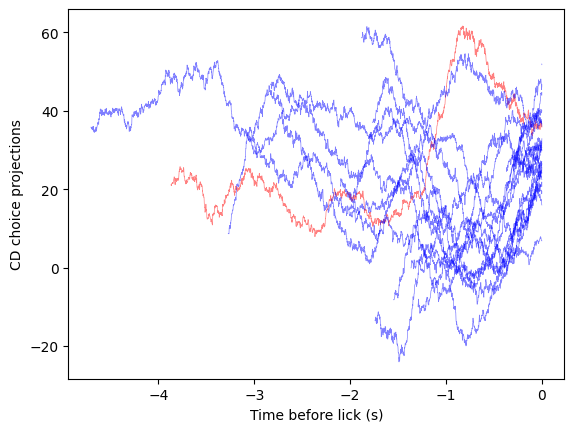

47 trials removed for stability reasons
only ppyr neurons: 295 --> 254
in house train test sorting
time taken: 35.71324944496155
calculation time: 0.3399639129638672


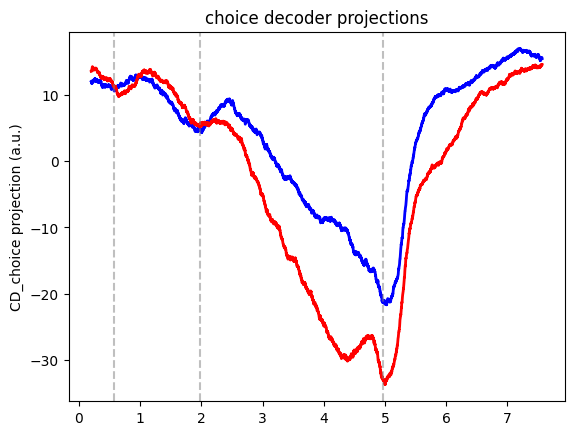

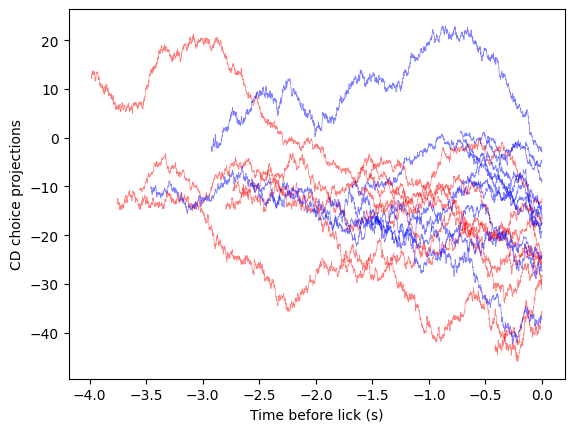

10 trials removed for stability reasons
only ppyr neurons: 295 --> 259
in house train test sorting
time taken: 33.261009216308594
calculation time: 0.3276066780090332


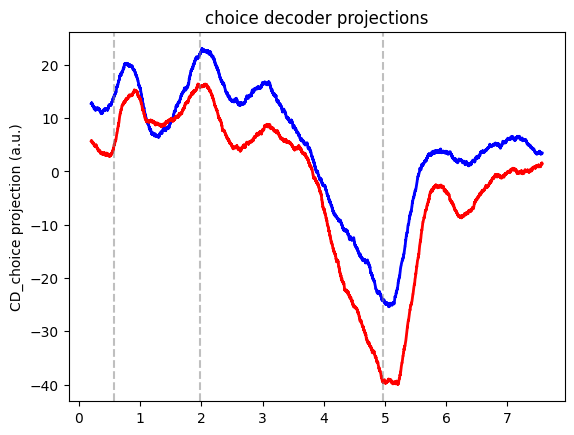

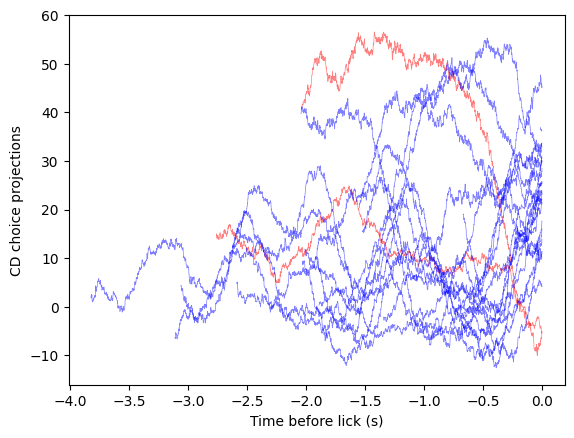

3 trials removed for stability reasons
only ppyr neurons: 310 --> 283
in house train test sorting
time taken: 46.09240460395813
calculation time: 0.3346560001373291


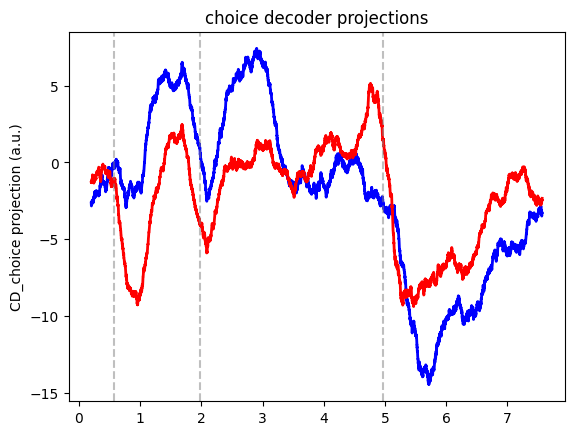

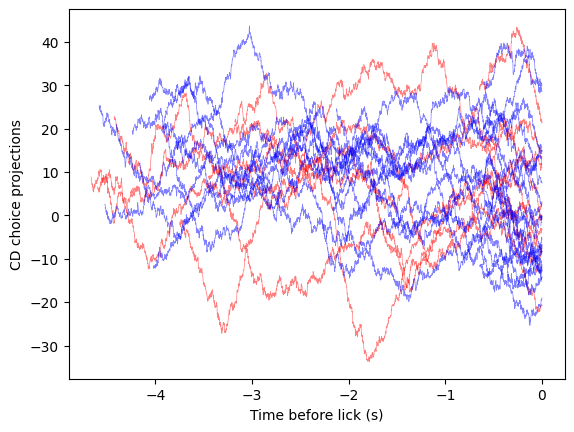

22 trials removed for stability reasons
only ppyr neurons: 422 --> 361
in house train test sorting
time taken: 69.27058339118958
calculation time: 0.44774627685546875


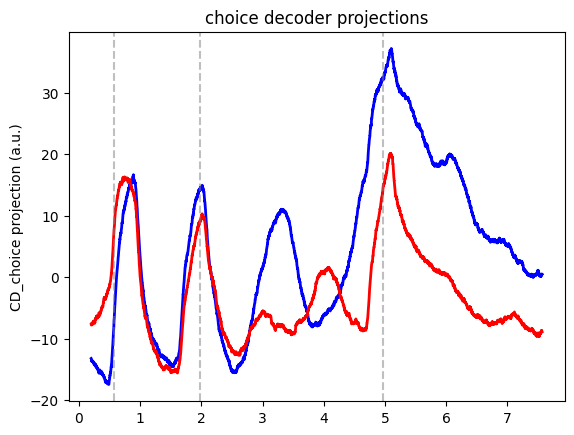

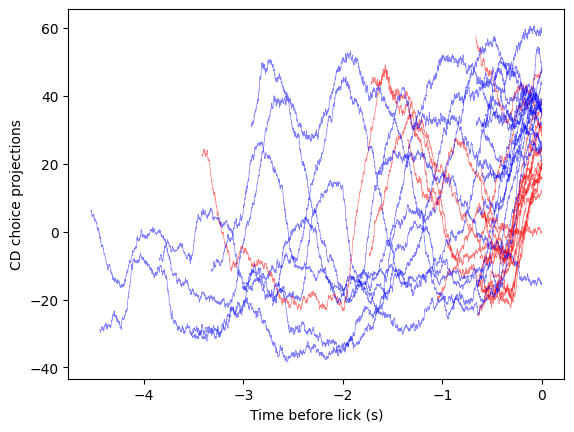

In [215]:

trial_threshold = 1

path =r'L:\data\CW68\python\2025_12_10'

all_avg_left = []
all_avg_right = []
all_std_left = []
all_std_right = []

for path in naive_paths:

    s1 = Mode(path, filter_low_perf=False, filter_by_stim=False)


    early_lick_trials = np.where(s1.early_lick)[0]
    early_lick_side = [i[0] for i in s1.early_lick_side] # use first lick as direction
    early_lick_time = [i[0][0] for i in s1.early_lick_time]
    # for now keep all the early licks (even in ITI)
    drop_idx = [i for i in range(len(early_lick_time)) if np.abs(0.57-early_lick_time[i]) < 0.2]
    # drop_idx = [i for i in range(len(early_lick_time)) if np.abs(1.2-early_lick_time[i]) > 0.2]
    drop_idx = [i for i in range(len(early_lick_time))]
    early_lick_trials = np.array(early_lick_trials)[drop_idx]
    early_lick_side = np.array(early_lick_side)[drop_idx]
    early_lick_time = np.array(early_lick_time)[drop_idx]


    early_lick_left, early_lick_right = [],[] #collect idx of el sides
    # for i in range(len(s1.early_lick_side)):
    for i in range(len(early_lick_side)):
        if early_lick_side[i] == 'l':
            early_lick_left += [i]
        else:
            early_lick_right += [i]
    stable_set = set.intersection(*(set(s1.stable_trials[n]) for n in s1.good_neurons))
    early_lick_left = [i for i in early_lick_left if not s1.stim_ON[early_lick_trials[i]] and early_lick_trials[i] in stable_set]
    early_lick_right = [i for i in early_lick_right if not s1.stim_ON[early_lick_trials[i]] and early_lick_trials[i] in stable_set]
    time = s1.t

    if len(early_lick_right) < trial_threshold or len(early_lick_left) < trial_threshold:
        print('Not enough trials to train')
        continue
    cd_choice, _ = s1.plot_CD(mode_input='choice')



    # single trial view
    f=plt.figure()

    left_proj = []
    for t in early_lick_left:
        time_adj = time[np.where(time<early_lick_time[t])]
        if len(time_adj) == 0:
            continue
        
        trial = early_lick_trials[t]
        activity, _, _ = s1.get_PSTH_multiple(s1.good_neurons, [trial], binsize=s1.binsize, timestep = s1.timestep)

        # activity = activity - np.tile(np.mean(activityRL_train, axis=1)[:, None], (1, activity.shape[1]))
        proj_allDim = np.dot(activity.T, cd_choice)
        # proj_allDimR += [proj_allDim]
        left_proj += [proj_allDim[:len(time_adj)]]
        plt.plot(time_adj - time_adj[-1], proj_allDim[:len(time_adj)], 'r', alpha = 0.5,  linewidth = 0.5)


    right_proj=[]
    for t in early_lick_right:
        time_adj = time[np.where(time<early_lick_time[t])]
        if len(time_adj) == 0:
            continue
        
        trial = early_lick_trials[t]
        activity, _, _ = s1.get_PSTH_multiple(s1.good_neurons, [trial], binsize=s1.binsize, timestep = s1.timestep)

        # activity = activity - np.tile(np.mean(activityRL_train, axis=1)[:, None], (1, activity.shape[1]))
        proj_allDim = np.dot(activity.T, cd_choice)
        # proj_allDimR += [proj_allDim]
        right_proj += [proj_allDim[:len(time_adj)]]
        plt.plot(time_adj - time_adj[-1], proj_allDim[:len(time_adj)], 'b', alpha = 0.5,  linewidth = 0.5)
        
    plt.xlabel('Time before lick (s)')
    plt.ylabel('CD choice projections')
    plt.show()

    if len(right_proj)==0 or len(left_proj) ==0:
        continue
    # population average view
    #average if there an item
    max_len = max(len(lst) for lst in left_proj) 
    time_left = time[:max_len] - time[max_len]
    avg_left,std_left = [], []
    for idx in range(1,max_len+1):
        
        vals = [i[-idx, 0] for i in left_proj if len(i)>idx]
        avg_left += [np.mean(vals)]
        std_left += [np.std(vals) / np.sqrt(len(vals))]
    avg_left.reverse()
    std_left.reverse()
    max_len = max(len(lst) for lst in right_proj)
    time_right = time[:max_len] - time[max_len]
    avg_right,std_right = [],[]
    for idx in range(1,max_len+1):
        
        vals = [i[-idx, 0] for i in right_proj if len(i)>idx]
        avg_right += [np.mean(vals)]
        std_right += [np.std(vals) / np.sqrt(len(vals))]

    avg_right.reverse()
    std_right.reverse()


    time_idx_right = np.where(time_right > -2)[0]
    time_idx_left = np.where(time_left > -2)[0]

    avg_left = np.array(avg_left)[time_idx_left]
    avg_right = np.array(avg_right)[time_idx_right]
    std_left = np.array(std_left)[time_idx_left]
    std_right = np.array(std_right)[time_idx_right]


    all_avg_left += [avg_left]
    all_avg_right += [avg_right]
    all_std_left += [std_left]
    all_std_right += [std_right]

# f = plt.figure()
# plt.plot(time_right, avg_right, color='b')
# plt.plot(time_left, avg_left, color='r')
# plt.fill_between(time_left, np.array(avg_left) - np.array(std_left), 
#          np.array(avg_left) + np.array(std_left),
#          color=['#ffaeb1'])
# plt.fill_between(time_right, np.array(avg_right) - np.array(std_right), 
#          np.array(avg_right) + np.array(std_right),
#          color=['#b4b2dc'])

# plt.xlabel('Time before lick (s)')
# plt.ylabel('CD choice projections')
# plt.show()


In [216]:
filt_av_right = [i for i in all_avg_right if len(i) > 1800]
filt_std_right = [i for i in all_std_right if len(i) > 1800]

filt_av_left = [i for i in all_avg_left if len(i) > 1800]
filt_std_left = [i for i in all_std_left if len(i) > 1800]

av_left = np.mean(filt_av_left, axis=0)
av_right = np.mean(filt_av_right, axis=0)
std_left = np.mean(filt_std_left, axis=0)
std_right = np.mean(filt_std_right, axis=0)



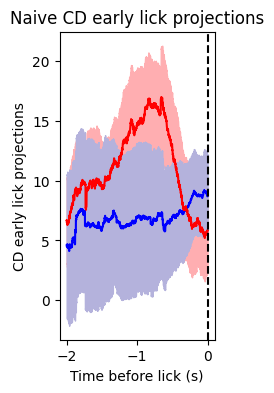

In [217]:
# av_right
time_trained = time_left[time_idx_left]
# trained_av_right, trained_av_left = np.array(av_right),np.array(av_left)
# trained_std_right, trained_std_left = np.array(std_right), np.array(std_left)

time_idx_right = np.where(time_right > -2)[0]
time_idx_left = np.where(time_left > -2)[0]

f = plt.figure(figsize=(2, 4))
plt.plot(time_right[time_idx_right], np.array(av_right), color='b')
plt.plot(time_right[time_idx_right], np.array(av_left), color='r')
plt.fill_between(time_right[time_idx_right], np.array(av_left) - np.array(std_left), 
         np.array(av_left) + np.array(std_left),
         color=['#ffaeb1'])
plt.fill_between(time_right[time_idx_right], np.array(av_right) - np.array(std_right), 
         np.array(av_right) + np.array(std_right),
         color=['#b4b2dc'])
plt.axvline(x=0, color='k', linestyle='--')
plt.xlabel('Time before lick (s)')
plt.ylabel('CD early lick projections')
plt.title('Naive CD early lick projections')
plt.show()

### Trained

Loading good trial inds from file
7 trials removed for stability reasons
only ppyr neurons: 305 --> 271
in house train test sorting
time taken: 37.971325397491455


c:\Users\catherinewang\AppData\Local\Programs\Python\Python38\lib\site-packages\numpy\core\fromnumeric.py:3464: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\catherinewang\AppData\Local\Programs\Python\Python38\lib\site-packages\numpy\core\_methods.py:184: RuntimeWarning: invalid value encountered in divide
  ret = um.true_divide(


calculation time: 0.358353853225708


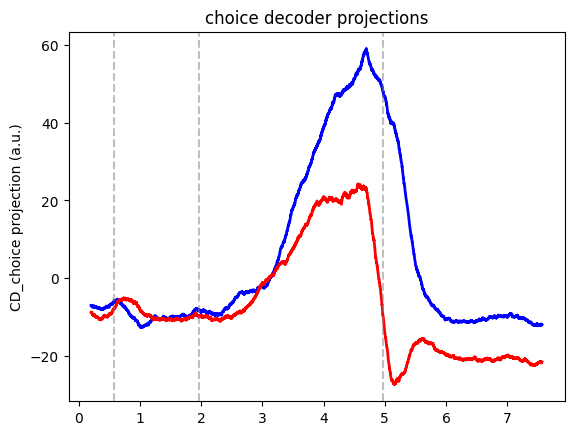

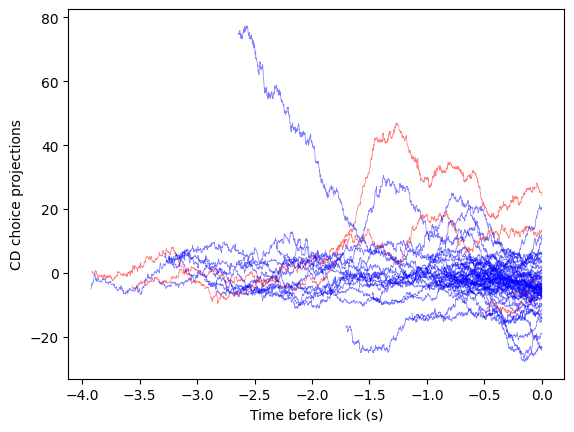

c:\Users\catherinewang\AppData\Local\Programs\Python\Python38\lib\site-packages\numpy\core\_methods.py:192: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
c:\Users\catherinewang\AppData\Local\Programs\Python\Python38\lib\site-packages\numpy\core\_methods.py:269: RuntimeWarning: Degrees of freedom <= 0 for slice
  ret = _var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
c:\Users\catherinewang\AppData\Local\Programs\Python\Python38\lib\site-packages\numpy\core\_methods.py:226: RuntimeWarning: invalid value encountered in divide
  arrmean = um.true_divide(arrmean, div, out=arrmean,
c:\Users\catherinewang\AppData\Local\Programs\Python\Python38\lib\site-packages\numpy\core\_methods.py:261: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


Loading good trial inds from file
0 trials removed for stability reasons
only ppyr neurons: 422 --> 377
in house train test sorting
time taken: 72.46319079399109
calculation time: 0.5640778541564941


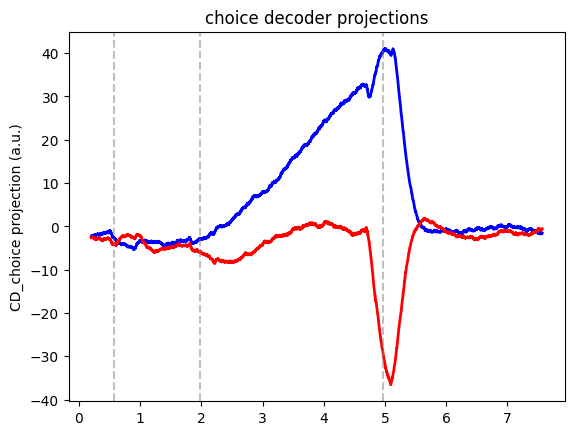

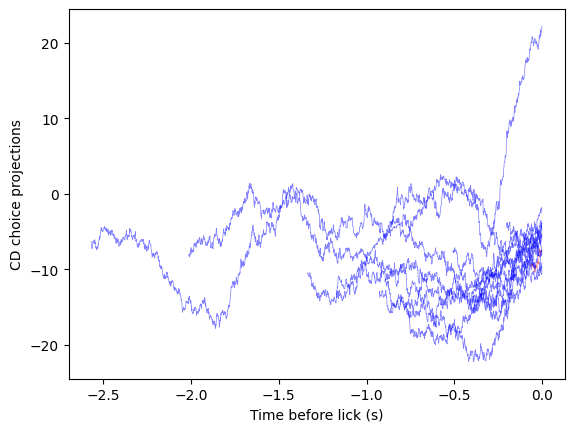

Loading good trial inds from file
20 trials removed for stability reasons
only ppyr neurons: 328 --> 291
in house train test sorting
time taken: 43.27187538146973
calculation time: 0.4972250461578369


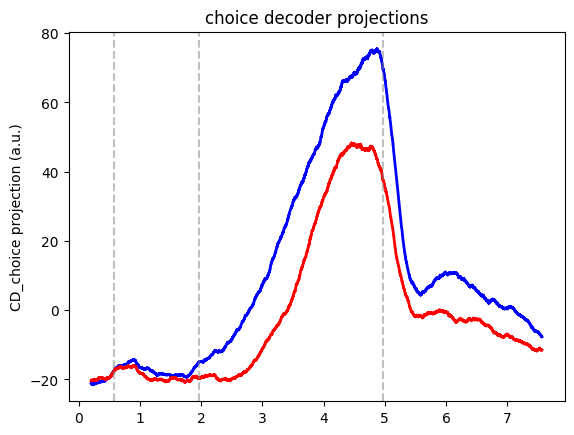

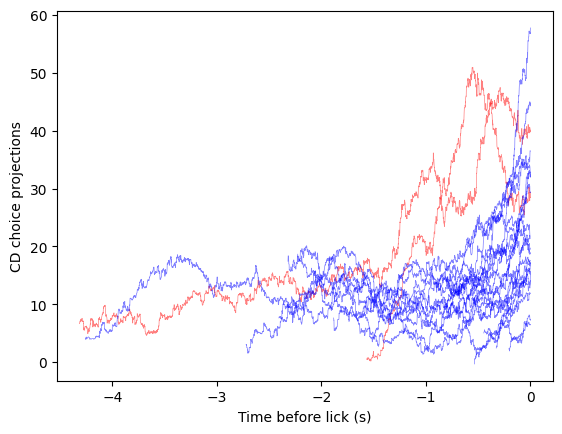

Loading good trial inds from file
15 trials removed for stability reasons
only ppyr neurons: 178 --> 154
in house train test sorting
time taken: 23.10461163520813
calculation time: 0.24646949768066406


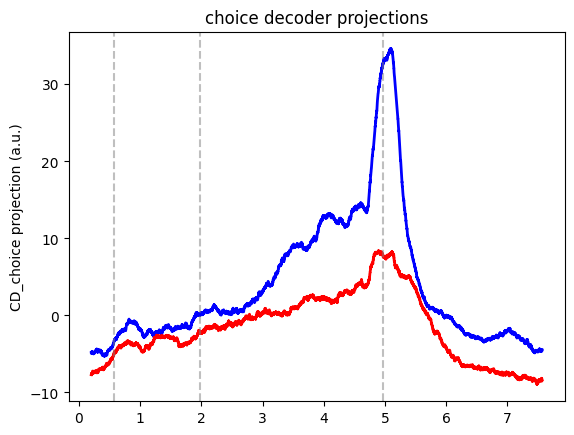

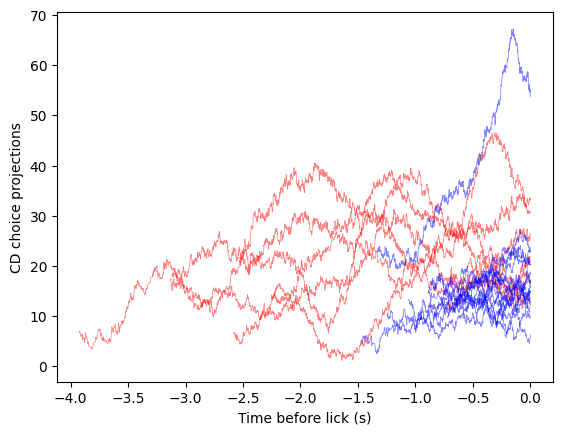

Loading good trial inds from file
22 trials removed for stability reasons
only ppyr neurons: 232 --> 203
in house train test sorting
time taken: 37.2355535030365
calculation time: 0.3738253116607666


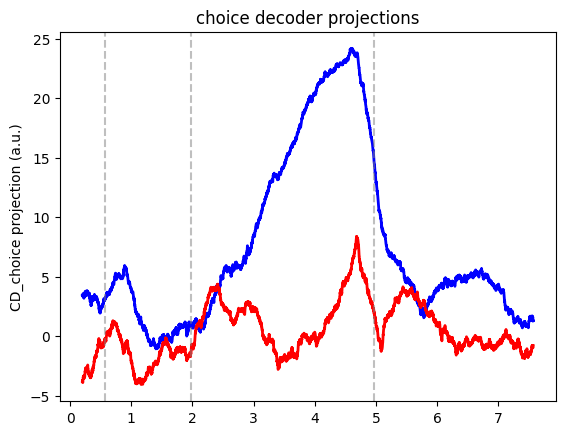

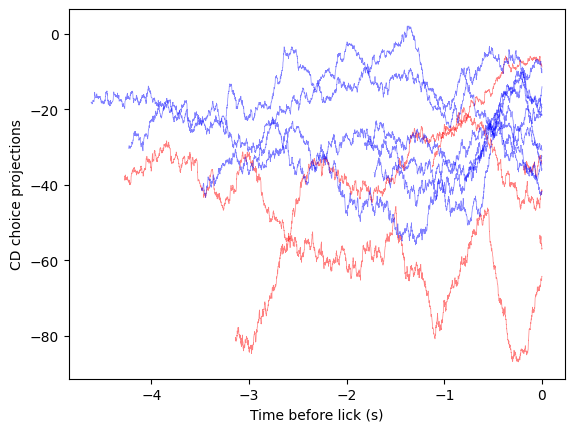

Loading good trial inds from file
33 trials removed for stability reasons
only ppyr neurons: 194 --> 184
in house train test sorting
time taken: 27.129801273345947
calculation time: 0.27105259895324707


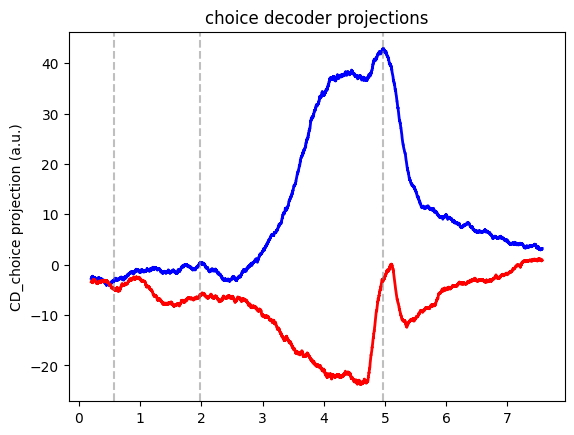

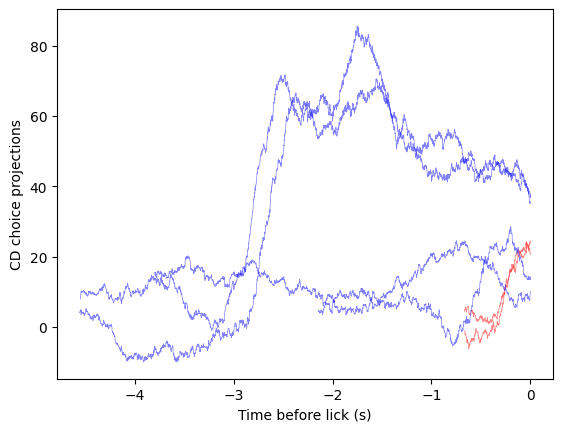

Loading good trial inds from file
0 trials removed for stability reasons
only ppyr neurons: 407 --> 363
in house train test sorting
time taken: 68.1448142528534
calculation time: 0.4459073543548584


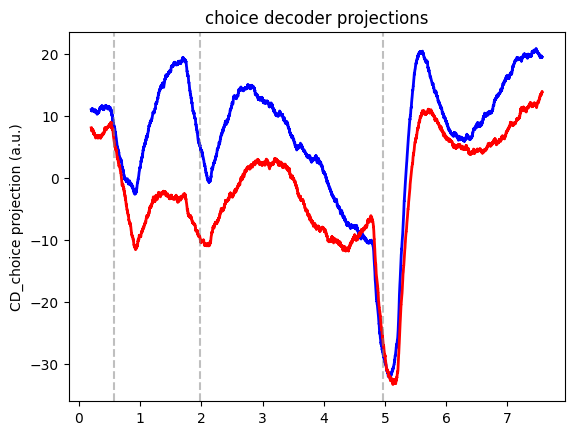

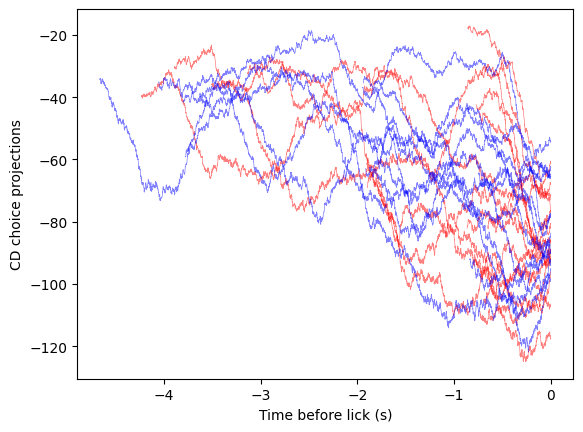

Loading good trial inds from file
0 trials removed for stability reasons
only ppyr neurons: 349 --> 298
in house train test sorting
time taken: 29.71290898323059
calculation time: 0.2824862003326416


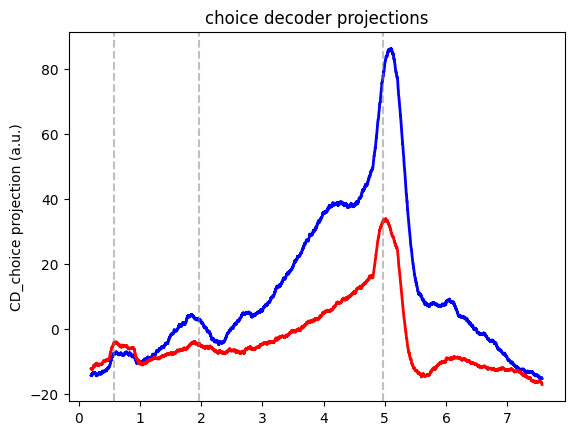

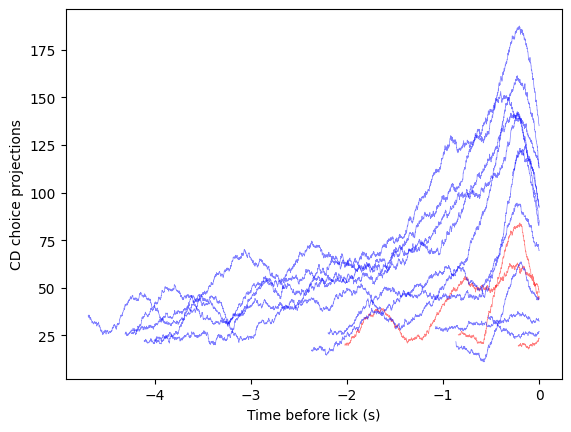

Loading good trial inds from file
4 trials removed for stability reasons
only ppyr neurons: 249 --> 220
in house train test sorting
time taken: 27.106139659881592
calculation time: 0.22690224647521973


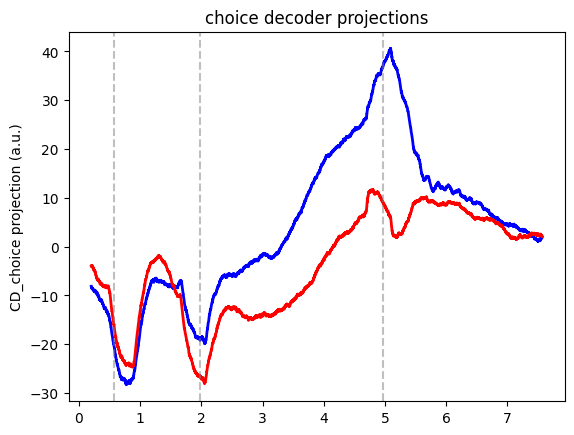

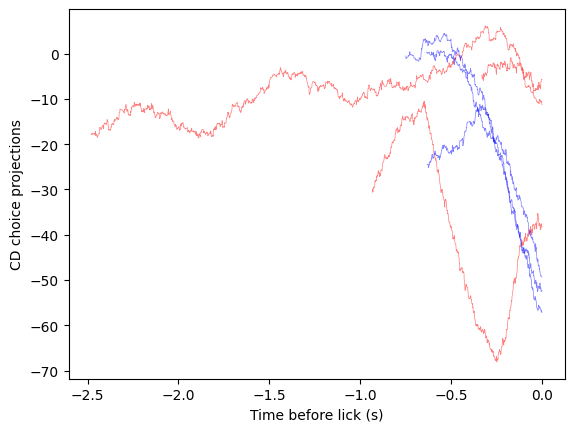

Loading good trial inds from file
14 trials removed for stability reasons
only ppyr neurons: 173 --> 157
in house train test sorting
time taken: 13.982892036437988
calculation time: 0.13449883460998535


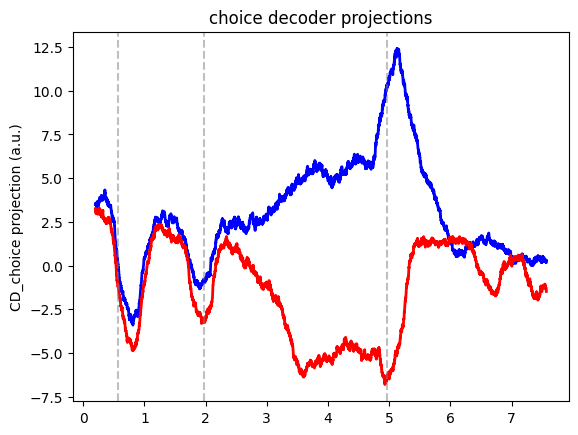

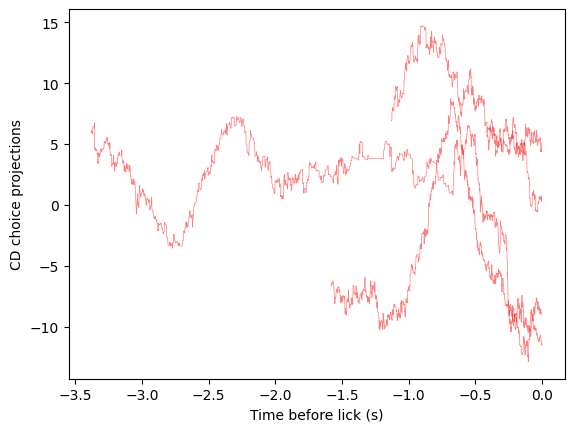

Loading good trial inds from file
29 trials removed for stability reasons
only ppyr neurons: 484 --> 432
in house train test sorting
time taken: 42.887569427490234
calculation time: 0.4938809871673584


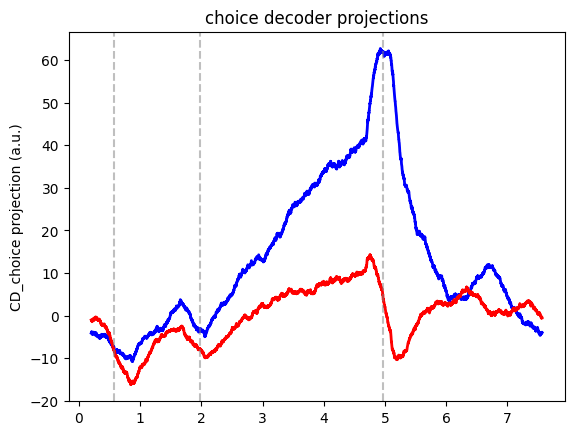

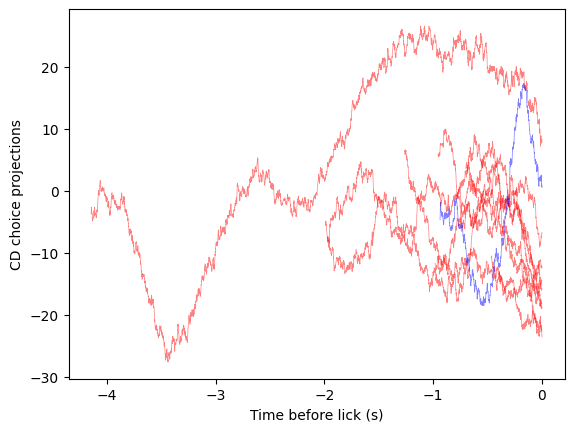

Loading good trial inds from file
15 trials removed for stability reasons
only ppyr neurons: 361 --> 328
in house train test sorting
time taken: 43.354217290878296
calculation time: 0.28958845138549805


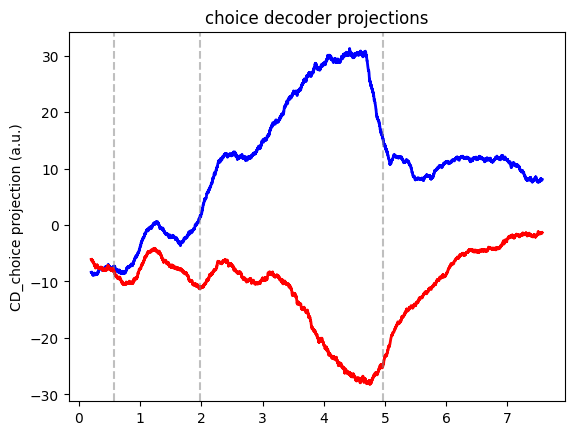

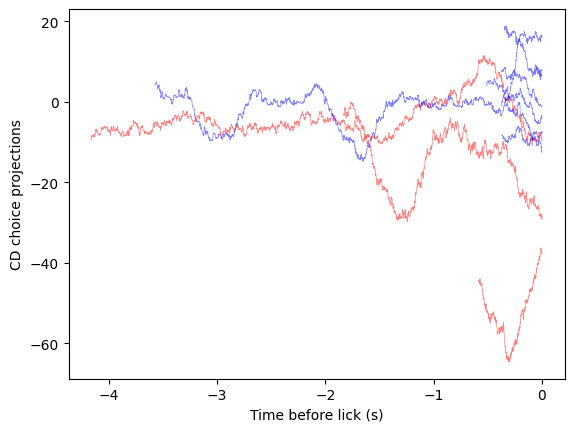

Loading good trial inds from file
28 trials removed for stability reasons
only ppyr neurons: 504 --> 447
in house train test sorting
time taken: 52.06427240371704
calculation time: 0.3468749523162842


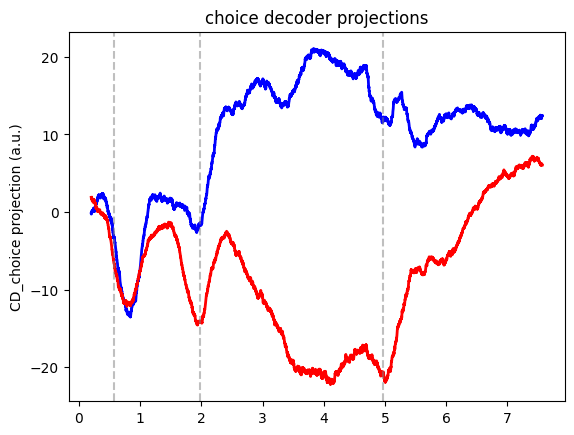

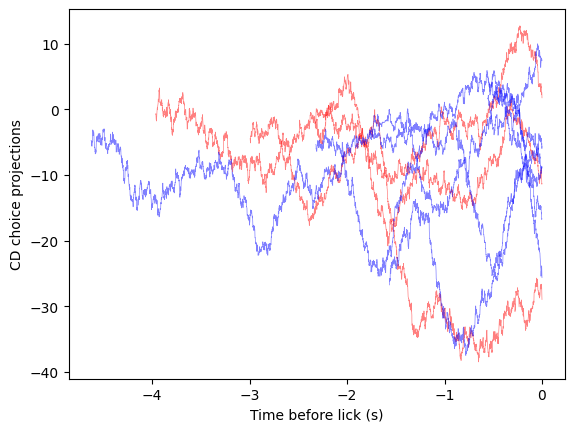

Loading good trial inds from file
32 trials removed for stability reasons
only ppyr neurons: 218 --> 196
in house train test sorting
time taken: 16.123881578445435
calculation time: 0.15211987495422363


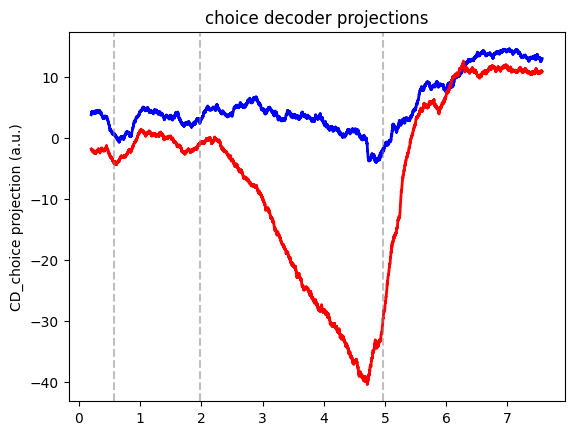

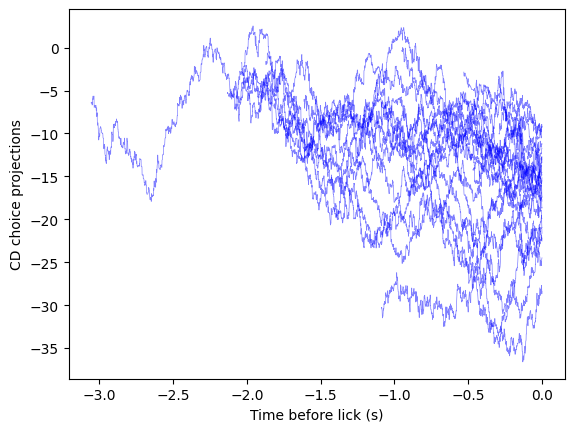

Loading good trial inds from file
0 trials removed for stability reasons
only ppyr neurons: 203 --> 176
in house train test sorting
time taken: 15.893312692642212
calculation time: 0.1397850513458252


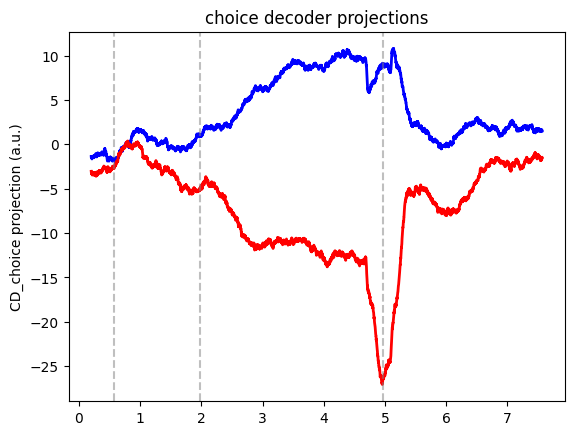

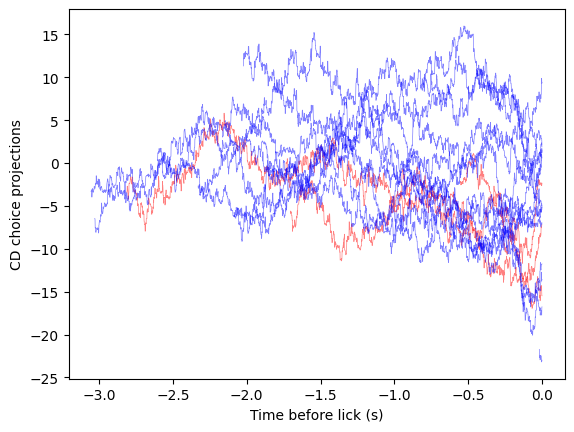

Loading good trial inds from file
6 trials removed for stability reasons
only ppyr neurons: 362 --> 303
in house train test sorting
time taken: 26.601198196411133
calculation time: 0.25664639472961426


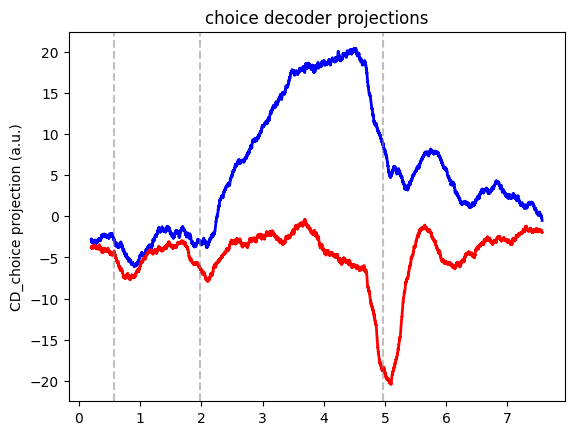

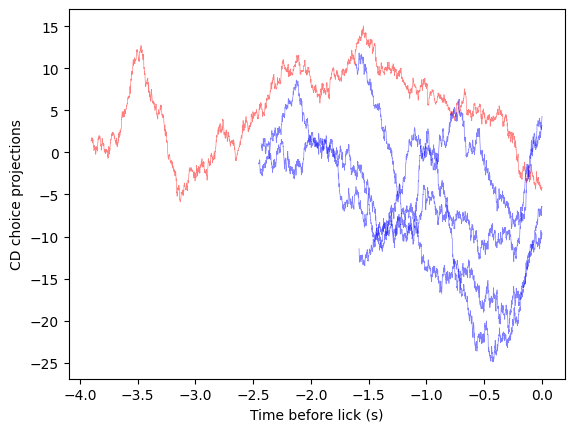

Loading good trial inds from file
10 trials removed for stability reasons
only ppyr neurons: 206 --> 180
in house train test sorting
time taken: 13.620972633361816
calculation time: 0.13463139533996582


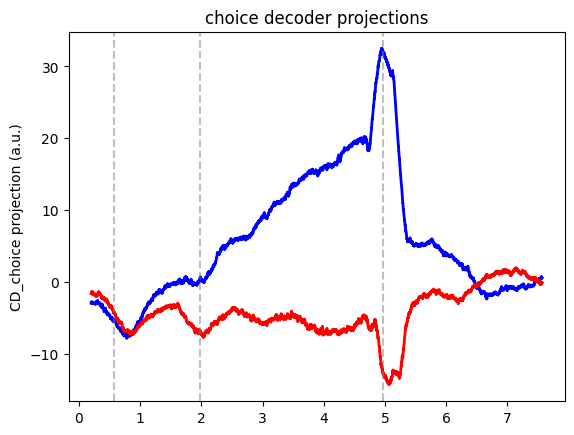

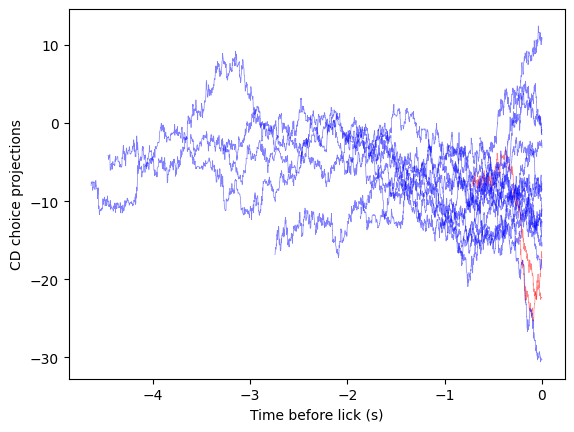

In [219]:

trial_threshold = 1

path =r'L:\data\CW68\python\2025_12_10'

all_avg_left = []
all_avg_right = []
all_std_left = []
all_std_right = []

for path in cat(trained_paths_high_performance):

    s1 = Mode(path, filter_low_perf=True, filter_by_stim=False)

    cd_choice, _ = s1.plot_CD(mode_input='choice')

    early_lick_trials = np.where(s1.early_lick)[0]
    early_lick_side = [i[0] for i in s1.early_lick_side] # use first lick as direction
    early_lick_time = [i[0][0] for i in s1.early_lick_time]
    # for now keep all the early licks (even in ITI)
    drop_idx = [i for i in range(len(early_lick_time)) if np.abs(0.57-early_lick_time[i]) < 0.2]
    # drop_idx = [i for i in range(len(early_lick_time)) if np.abs(1.2-early_lick_time[i]) > 0.2]
    drop_idx = [i for i in range(len(early_lick_time))]
    early_lick_trials = np.array(early_lick_trials)[drop_idx]
    early_lick_side = np.array(early_lick_side)[drop_idx]
    early_lick_time = np.array(early_lick_time)[drop_idx]


    early_lick_left, early_lick_right = [],[] #collect idx of el sides
    # for i in range(len(s1.early_lick_side)):
    for i in range(len(early_lick_side)):
        if early_lick_side[i] == 'l':
            early_lick_left += [i]
        else:
            early_lick_right += [i]
    stable_set = set.intersection(*(set(s1.stable_trials[n]) for n in s1.good_neurons))
    early_lick_left = [i for i in early_lick_left if not s1.stim_ON[early_lick_trials[i]] and early_lick_trials[i] in stable_set]
    early_lick_right = [i for i in early_lick_right if not s1.stim_ON[early_lick_trials[i]] and early_lick_trials[i] in stable_set]
    time = s1.t

    if len(early_lick_right) < trial_threshold or len(early_lick_left) < trial_threshold:
        print('Not enough trials to train')
        continue



    # single trial view
    f=plt.figure()

    left_proj = []
    for t in early_lick_left:
        time_adj = time[np.where(time<early_lick_time[t])]
        if len(time_adj) == 0:
            continue
        
        trial = early_lick_trials[t]
        activity, _, _ = s1.get_PSTH_multiple(s1.good_neurons, [trial], binsize=s1.binsize, timestep = s1.timestep)

        # activity = activity - np.tile(np.mean(activityRL_train, axis=1)[:, None], (1, activity.shape[1]))
        proj_allDim = np.dot(activity.T, cd_choice)
        # proj_allDimR += [proj_allDim]
        left_proj += [proj_allDim[:len(time_adj)]]
        plt.plot(time_adj - time_adj[-1], proj_allDim[:len(time_adj)], 'r', alpha = 0.5,  linewidth = 0.5)


    right_proj=[]
    for t in early_lick_right:
        time_adj = time[np.where(time<early_lick_time[t])]
        if len(time_adj) == 0:
            continue
        
        trial = early_lick_trials[t]
        activity, _, _ = s1.get_PSTH_multiple(s1.good_neurons, [trial], binsize=s1.binsize, timestep = s1.timestep)

        # activity = activity - np.tile(np.mean(activityRL_train, axis=1)[:, None], (1, activity.shape[1]))
        proj_allDim = np.dot(activity.T, cd_choice)
        # proj_allDimR += [proj_allDim]
        right_proj += [proj_allDim[:len(time_adj)]]
        plt.plot(time_adj - time_adj[-1], proj_allDim[:len(time_adj)], 'b', alpha = 0.5,  linewidth = 0.5)
        
    plt.xlabel('Time before lick (s)')
    plt.ylabel('CD choice projections')
    plt.show()

    if len(right_proj)==0 or len(left_proj) ==0:
        continue
    # population average view
    #average if there an item
    max_len = max(len(lst) for lst in left_proj) 
    time_left = time[:max_len] - time[max_len]
    avg_left,std_left = [], []
    for idx in range(1,max_len+1):
        
        vals = [i[-idx, 0] for i in left_proj if len(i)>idx]
        avg_left += [np.mean(vals)]
        std_left += [np.std(vals) / np.sqrt(len(vals))]
    avg_left.reverse()
    std_left.reverse()
    max_len = max(len(lst) for lst in right_proj)
    time_right = time[:max_len] - time[max_len]
    avg_right,std_right = [],[]
    for idx in range(1,max_len+1):
        
        vals = [i[-idx, 0] for i in right_proj if len(i)>idx]
        avg_right += [np.mean(vals)]
        std_right += [np.std(vals) / np.sqrt(len(vals))]

    avg_right.reverse()
    std_right.reverse()


    time_idx_right = np.where(time_right > -2)[0]
    time_idx_left = np.where(time_left > -2)[0]

    avg_left = np.array(avg_left)[time_idx_left]
    avg_right = np.array(avg_right)[time_idx_right]
    std_left = np.array(std_left)[time_idx_left]
    std_right = np.array(std_right)[time_idx_right]


    all_avg_left += [avg_left]
    all_avg_right += [avg_right]
    all_std_left += [std_left]
    all_std_right += [std_right]

# f = plt.figure()
# plt.plot(time_right, avg_right, color='b')
# plt.plot(time_left, avg_left, color='r')
# plt.fill_between(time_left, np.array(avg_left) - np.array(std_left), 
#          np.array(avg_left) + np.array(std_left),
#          color=['#ffaeb1'])
# plt.fill_between(time_right, np.array(avg_right) - np.array(std_right), 
#          np.array(avg_right) + np.array(std_right),
#          color=['#b4b2dc'])

# plt.xlabel('Time before lick (s)')
# plt.ylabel('CD choice projections')
# plt.show()


In [220]:
filt_av_right = [i for i in all_avg_right if len(i) > 1800]
filt_std_right = [i for i in all_std_right if len(i) > 1800]

filt_av_left = [i for i in all_avg_left if len(i) > 1800]
filt_std_left = [i for i in all_std_left if len(i) > 1800]

idx = [0,1,3,5,6,8]

In [221]:
av_left = np.mean(filt_av_left, axis=0)
av_right = np.mean(filt_av_right, axis=0)
std_left = np.mean(filt_std_left, axis=0)
std_right = np.mean(filt_std_right, axis=0)

# av_right


In [222]:
 np.array(av_right).shape, time_idx_left.shape, time_idx_right.shape

((1999,), (725,), (1999,))

In [223]:
time_trained = time_left[time_idx_left]
trained_av_right, trained_av_left = np.array(av_right),np.array(av_left)
trained_std_right, trained_std_left = np.array(std_right), np.array(std_left)

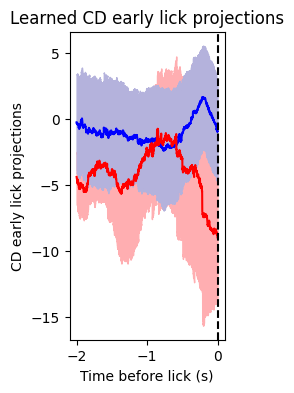

In [224]:
time_idx_right = np.where(time_right > -2)[0]
time_idx_left = np.where(time_left > -2)[0]

f = plt.figure(figsize=(2, 4))
plt.plot(time_right[time_idx_right], np.array(trained_av_right), color='b')
plt.plot(time_right[time_idx_right], np.array(trained_av_left), color='r')
plt.fill_between(time_right[time_idx_right], np.array(trained_av_left) - np.array(trained_std_left), 
         np.array(trained_av_left) + np.array(trained_std_left),
         color=['#ffaeb1'])
plt.fill_between(time_right[time_idx_right], np.array(trained_av_right) - np.array(trained_std_right), 
         np.array(trained_av_right) + np.array(trained_std_right),
         color=['#b4b2dc'])
plt.axvline(x=0, color='k', linestyle='--')
plt.xlabel('Time before lick (s)')
plt.ylabel('CD early lick projections')
plt.title('Learned CD early lick projections')
plt.show()

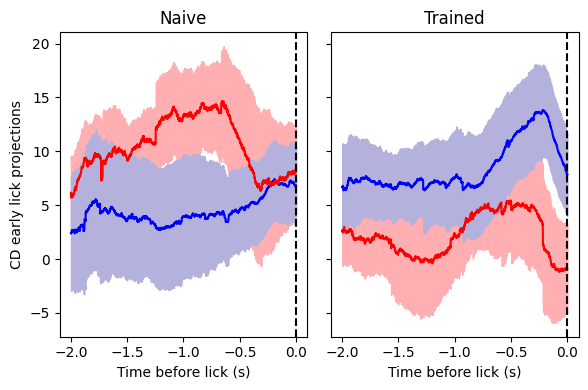

In [213]:

fig, axs = plt.subplots(1, 2, figsize=(6, 4), sharey=True)

# Naive
axs[0].plot(time_right[time_idx_right], np.array(av_right), color='b', label='Naive Right')
axs[0].plot(time_right[time_idx_right], np.array(av_left), color='r', label='Naive Left')
axs[0].fill_between(time_right[time_idx_right], np.array(av_left) - np.array(std_left), 
                   np.array(av_left) + np.array(std_left), color='#ffaeb1')
axs[0].fill_between(time_right[time_idx_right], np.array(av_right) - np.array(std_right), 
                   np.array(av_right) + np.array(std_right), color='#b4b2dc')
axs[0].axvline(x=0, color='k', linestyle='--')
axs[0].set_xlabel('Time before lick (s)')
axs[0].set_ylabel('CD early lick projections')
axs[0].set_title('Naive')

# Trained
axs[1].plot(time_trained, trained_av_right, color='b', label='Trained Right')
axs[1].plot(time_trained, trained_av_left, color='r', label='Trained Left')
axs[1].fill_between(time_trained, trained_av_left - trained_std_left, 
                   trained_av_left + trained_std_left, color='#ffaeb1')
axs[1].fill_between(time_trained, trained_av_right - trained_std_right, 
                   trained_av_right + trained_std_right, color='#b4b2dc')
axs[1].axvline(x=0, color='k', linestyle='--')
axs[1].set_xlabel('Time before lick (s)')
axs[1].set_title('Trained')

plt.tight_layout()
plt.show()

## Plot EL selectivity instead

Loading good trial inds from file
0 trials removed for stability reasons
only ppyr neurons: 216 --> 186
in house train test sorting
time taken: 15.438863515853882
calculation time: 0.14965152740478516


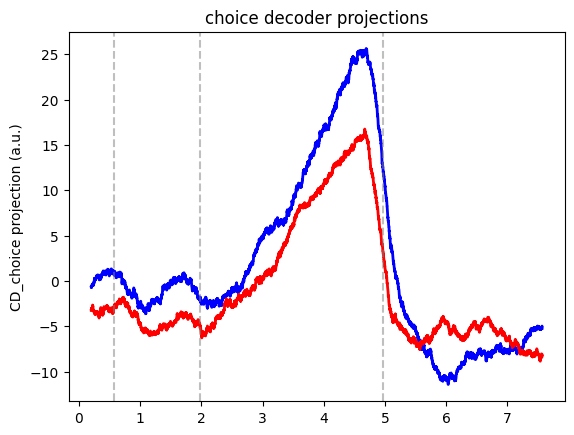

Loading good trial inds from file
7 trials removed for stability reasons
only ppyr neurons: 305 --> 271
in house train test sorting
time taken: 35.97882056236267
calculation time: 0.27925682067871094


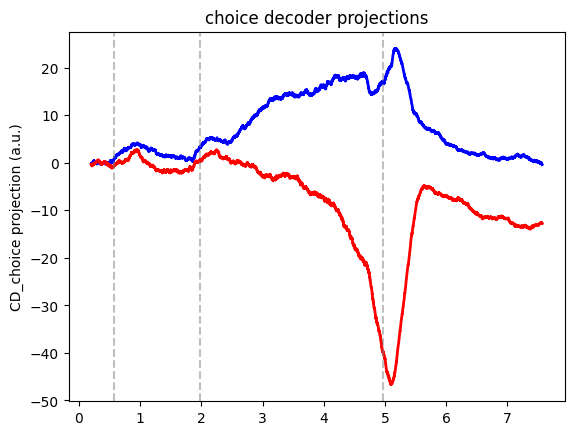

Loading good trial inds from file
0 trials removed for stability reasons
only ppyr neurons: 422 --> 377
in house train test sorting
time taken: 72.72488570213318
calculation time: 0.4659137725830078


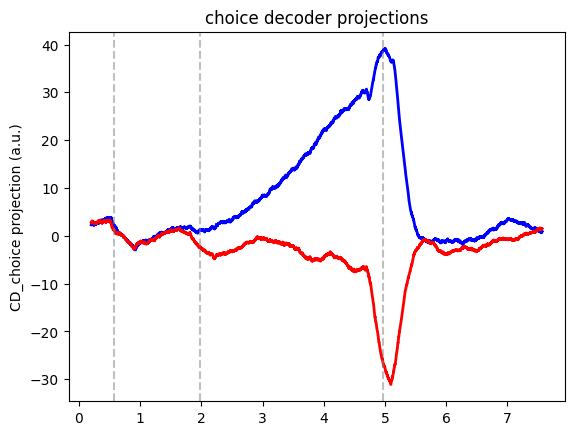

Loading good trial inds from file
20 trials removed for stability reasons
only ppyr neurons: 328 --> 291
in house train test sorting
time taken: 44.52501153945923
calculation time: 0.35902881622314453


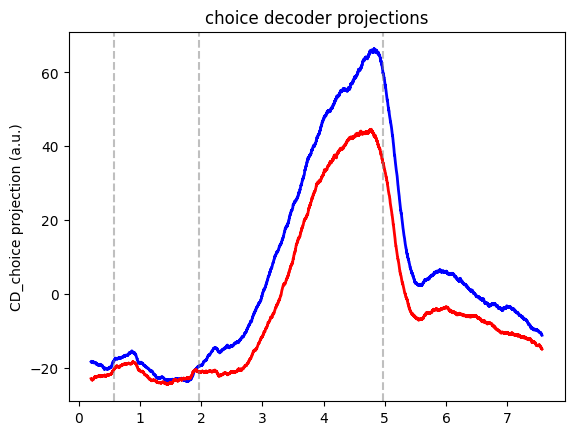

Loading good trial inds from file
15 trials removed for stability reasons
only ppyr neurons: 178 --> 154
in house train test sorting
time taken: 18.26833748817444
calculation time: 0.22168326377868652


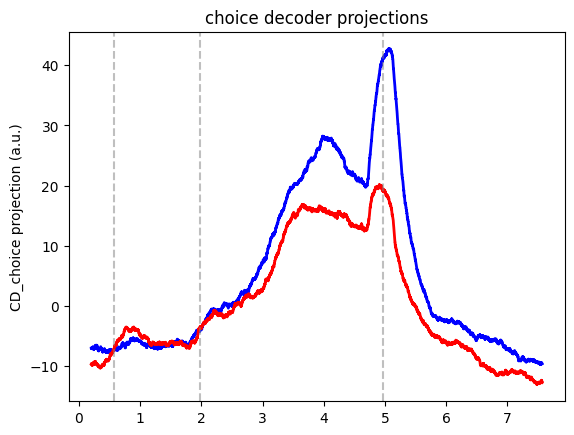

Loading good trial inds from file
0 trials removed for stability reasons
only ppyr neurons: 407 --> 363
in house train test sorting
time taken: 53.55679893493652
calculation time: 0.49356532096862793


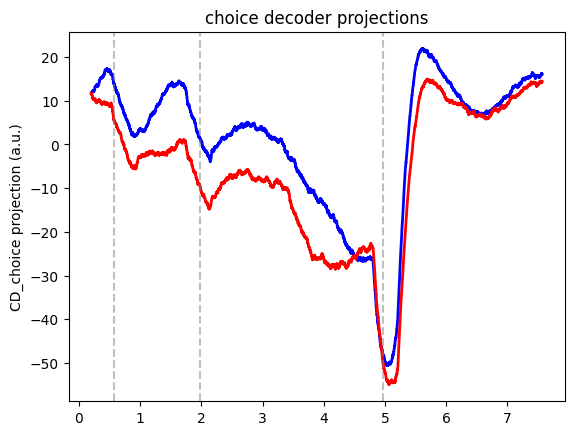

Loading good trial inds from file
0 trials removed for stability reasons
only ppyr neurons: 271 --> 245
in house train test sorting
time taken: 34.99243640899658
calculation time: 0.31248974800109863


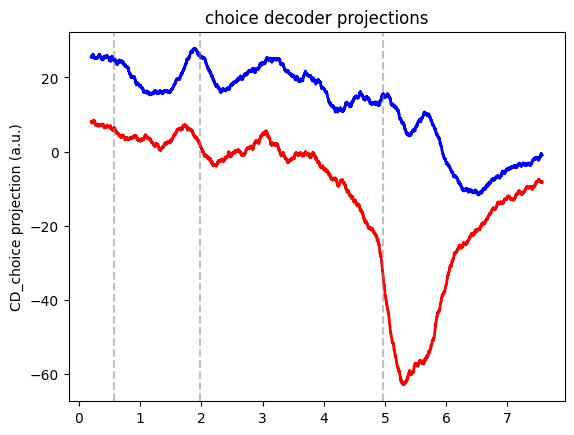

Not enough trials to train
Loading good trial inds from file
0 trials removed for stability reasons
only ppyr neurons: 344 --> 299
in house train test sorting
time taken: 42.67966318130493
calculation time: 0.4269120693206787


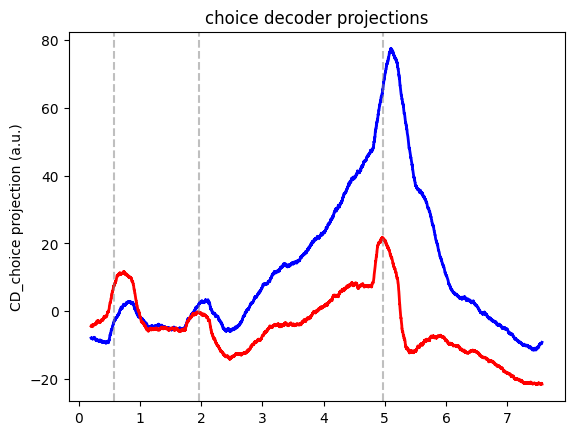

Loading good trial inds from file
0 trials removed for stability reasons
only ppyr neurons: 349 --> 298
in house train test sorting
time taken: 34.18363571166992
calculation time: 0.39954400062561035


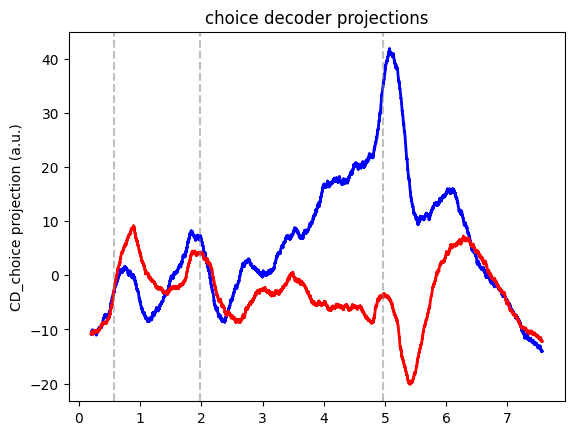

Not enough trials to train
Loading good trial inds from file
4 trials removed for stability reasons
only ppyr neurons: 249 --> 220
in house train test sorting
time taken: 32.50763511657715
calculation time: 0.28195619583129883


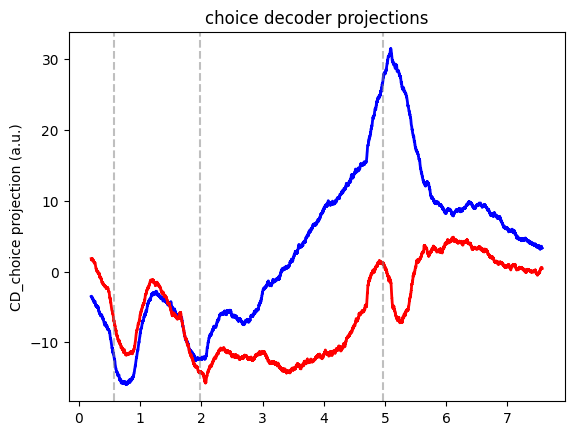

Loading good trial inds from file
14 trials removed for stability reasons
only ppyr neurons: 173 --> 157
in house train test sorting
time taken: 16.61068034172058
calculation time: 0.17774510383605957


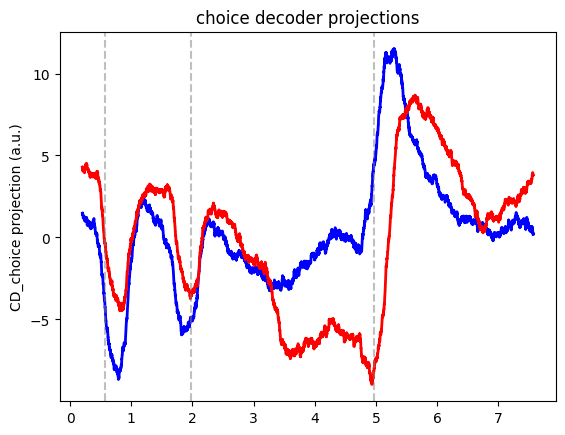

Not enough trials to train
Loading good trial inds from file
0 trials removed for stability reasons
only ppyr neurons: 343 --> 312
in house train test sorting
time taken: 58.463740825653076
calculation time: 0.4099891185760498


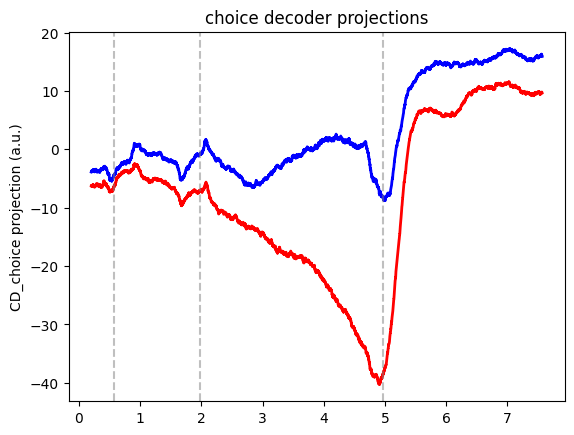

Not enough trials to train
Loading good trial inds from file
0 trials removed for stability reasons
only ppyr neurons: 516 --> 458
in house train test sorting
time taken: 95.6426637172699
calculation time: 0.5765671730041504


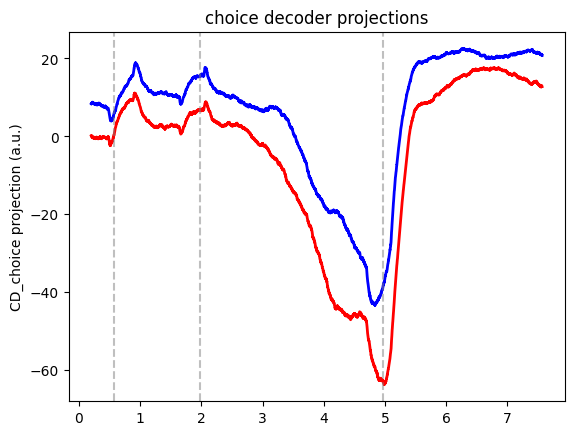

Not enough trials to train
Loading good trial inds from file
15 trials removed for stability reasons
only ppyr neurons: 361 --> 328
in house train test sorting
time taken: 55.00546956062317
calculation time: 0.27417492866516113


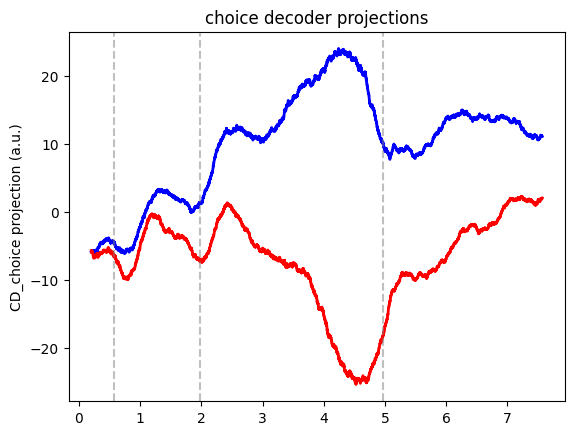

Loading good trial inds from file
14 trials removed for stability reasons
only ppyr neurons: 321 --> 283
in house train test sorting
time taken: 47.15186643600464
calculation time: 0.32407259941101074


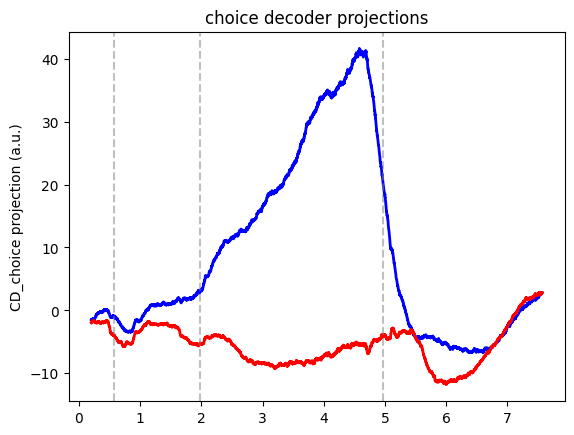

Not enough trials to train
Loading good trial inds from file
28 trials removed for stability reasons
only ppyr neurons: 504 --> 447
in house train test sorting
time taken: 71.85716128349304
calculation time: 0.5644032955169678


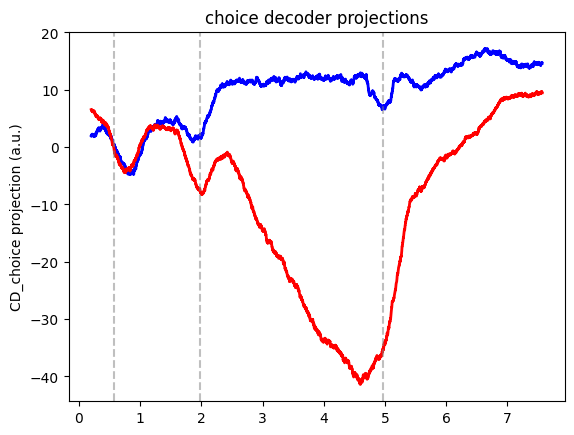

Not enough trials to train
4 trials removed for stability reasons
only ppyr neurons: 368 --> 321
in house train test sorting
time taken: 64.14480638504028
calculation time: 0.41185784339904785


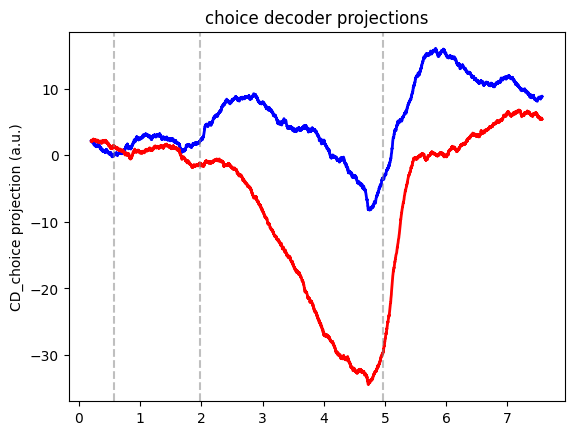

Loading good trial inds from file
32 trials removed for stability reasons
only ppyr neurons: 218 --> 196
in house train test sorting
time taken: 20.688539266586304
calculation time: 0.20322442054748535


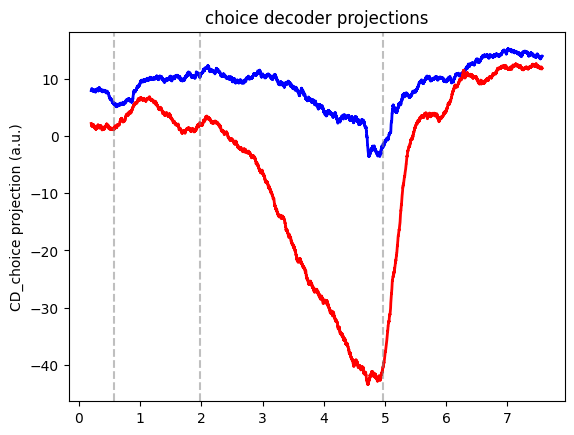

Not enough trials to train
Loading good trial inds from file
0 trials removed for stability reasons
only ppyr neurons: 203 --> 176
in house train test sorting
time taken: 20.725867748260498
calculation time: 0.22548627853393555


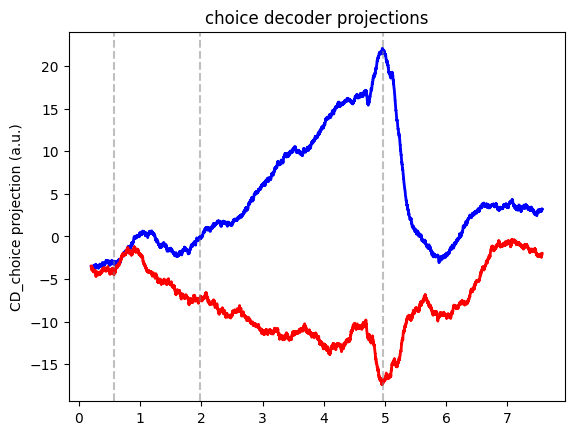

Not enough trials to train
Loading good trial inds from file
6 trials removed for stability reasons
only ppyr neurons: 362 --> 303
in house train test sorting
time taken: 35.64158272743225
calculation time: 0.398331880569458


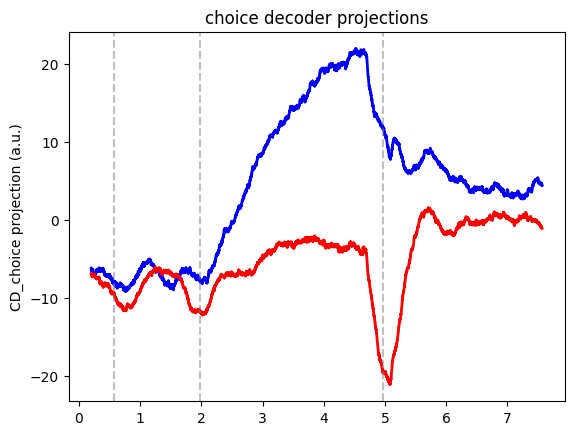

Not enough trials to train
Loading good trial inds from file
10 trials removed for stability reasons
only ppyr neurons: 206 --> 180
in house train test sorting
time taken: 15.903582334518433
calculation time: 0.2414100170135498


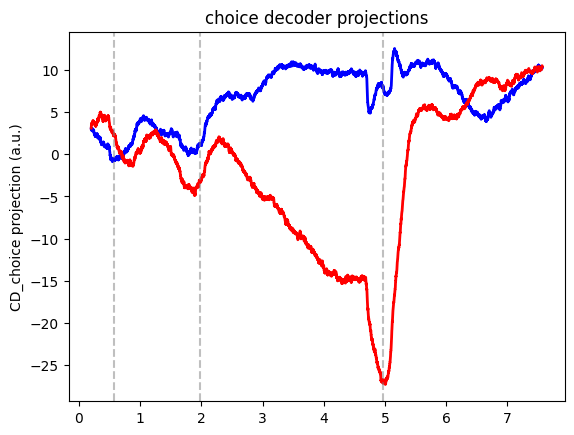

Not enough trials to train


In [141]:
# sort w CD values

p=0.01

all_sel_traces_delay_EL = []

trial_threshold = 4
time_before = 0.5
binsize=250
timestep=50

for path in cat(trained_paths):

    s1 = Mode(path, filter_low_perf=False, filter_by_stim=False)

    cd_choice, _ = s1.plot_CD(mode_input='choice')

    early_lick_trials = np.where(s1.early_lick)[0]
    early_lick_side = [i[0] for i in s1.early_lick_side] # use first lick as direction
    early_lick_time = [i[0][0] for i in s1.early_lick_time]
    # for now keep all the early licks (even in ITI)
    drop_idx = [i for i in range(len(early_lick_time)) if np.abs(0.57-early_lick_time[i]) < 0.2]
    # drop_idx = [i for i in range(len(early_lick_time)) if np.abs(1.2-early_lick_time[i]) > 0.2]
    drop_idx = [i for i in range(len(early_lick_time))]
    early_lick_trials = np.array(early_lick_trials)[drop_idx]
    early_lick_side = np.array(early_lick_side)[drop_idx]
    early_lick_time = np.array(early_lick_time)[drop_idx]


    early_lick_left, early_lick_right = [],[] #collect idx of el sides
    # for i in range(len(s1.early_lick_side)):
    for i in range(len(early_lick_side)):
        if early_lick_side[i] == 'l':
            early_lick_left += [i]
        else:
            early_lick_right += [i]
    early_lick_left = [i for i in early_lick_left if early_lick_trials[i] in s1.i_good_trials]
    early_lick_right = [i for i in early_lick_right if early_lick_trials[i] in s1.i_good_trials]
    time = s1.t

    if len(early_lick_right) < trial_threshold or len(early_lick_left) < trial_threshold:
        print('Not enough trials to train')
        continue


In [171]:
# [z_score_normalize(i) for i in L_traces[:, idx]]

# np.mean(L_traces_mod,axis=0)[:,0,:]
# np.array(L_traces_mod).shape
L_traces_mod, R_traces_mod

([[array([[-0.85406852, -0.85406852, -0.85406852, -1.78747673, -1.78747673,
           -1.78747673, -1.78747673, -1.78747673, -1.78747673, -1.78747673,
           -1.78747673, -1.78747673, -1.78747673, -1.78747673, -1.78747673,
           -1.78747673, -1.78747673, -1.78747673, -1.78747673, -1.78747673,
           -1.78747673, -1.78747673, -1.78747673, -0.85406852, -0.85406852,
           -0.85406852, -0.85406852, -0.85406852, -0.85406852, -0.85406852,
           -0.85406852, -0.85406852, -0.85406852, -0.85406852, -0.85406852,
           -0.85406852, -0.85406852, -0.85406852, -0.85406852, -0.85406852,
           -0.85406852, -0.85406852, -0.85406852, -1.78747673, -1.78747673,
           -1.78747673, -1.78747673, -1.78747673, -1.78747673, -1.78747673,
           -1.78747673, -1.78747673, -1.78747673, -1.78747673, -1.78747673,
           -1.78747673, -1.78747673, -1.78747673, -1.78747673, -1.78747673,
           -0.85406852, -0.85406852, -0.85406852, -0.85406852, -0.85406852,
           -

Loading good trial inds from file
0 trials removed for stability reasons
only ppyr neurons: 216 --> 186
in house train test sorting
time taken: 17.203278064727783


c:\Users\catherinewang\AppData\Local\Programs\Python\Python38\lib\site-packages\numpy\core\fromnumeric.py:3464: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\catherinewang\AppData\Local\Programs\Python\Python38\lib\site-packages\numpy\core\_methods.py:184: RuntimeWarning: invalid value encountered in divide
  ret = um.true_divide(


calculation time: 0.23933148384094238


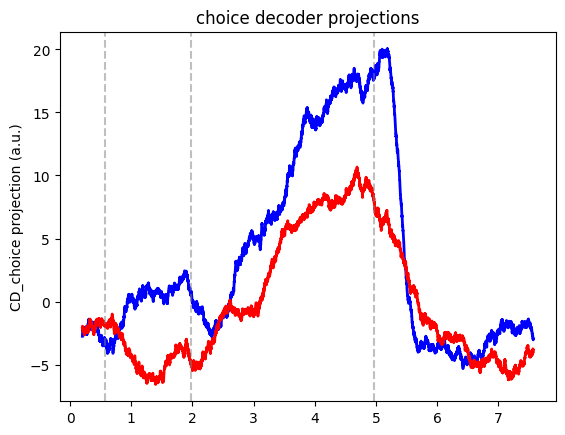

C:\Users\catherinewang\AppData\Local\Temp\ipykernel_19536\2304080745.py:2: RuntimeWarning: invalid value encountered in divide
  return (data - np.mean(data)) / np.std(data)


Loading good trial inds from file
7 trials removed for stability reasons
only ppyr neurons: 305 --> 271
in house train test sorting
time taken: 36.769208908081055
Not enough trials to train
Loading good trial inds from file
0 trials removed for stability reasons
only ppyr neurons: 422 --> 377
in house train test sorting
time taken: 74.78906083106995
Not enough trials to train
Loading good trial inds from file
20 trials removed for stability reasons
only ppyr neurons: 328 --> 291
in house train test sorting
time taken: 43.87353444099426
calculation time: 0.338850736618042


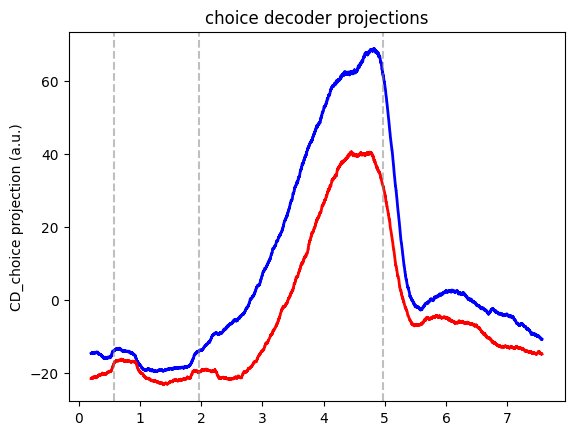

Loading good trial inds from file
15 trials removed for stability reasons
only ppyr neurons: 178 --> 154
in house train test sorting
time taken: 18.82441210746765
Not enough trials to train
Loading good trial inds from file
0 trials removed for stability reasons
only ppyr neurons: 407 --> 363
in house train test sorting
time taken: 54.778807163238525
calculation time: 0.46769022941589355


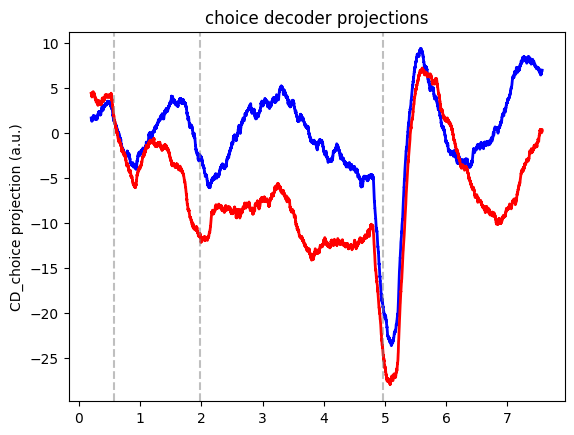

Loading good trial inds from file
0 trials removed for stability reasons
only ppyr neurons: 271 --> 245
in house train test sorting
time taken: 35.45524263381958
Not enough trials to train
Loading good trial inds from file
0 trials removed for stability reasons
only ppyr neurons: 344 --> 299
in house train test sorting
time taken: 43.528616428375244
calculation time: 0.36583447456359863


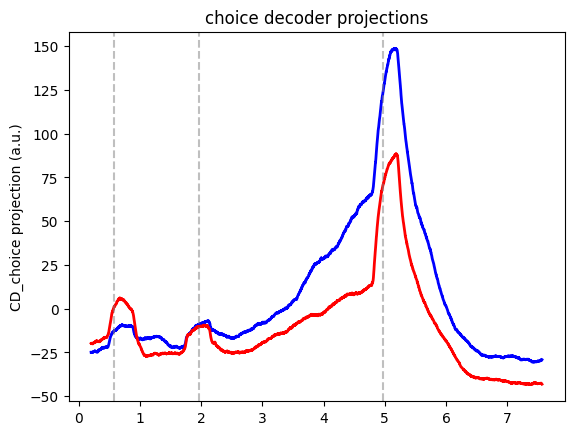

Loading good trial inds from file
0 trials removed for stability reasons
only ppyr neurons: 349 --> 298
in house train test sorting
time taken: 34.27703142166138
Not enough trials to train
Loading good trial inds from file
4 trials removed for stability reasons
only ppyr neurons: 249 --> 220
in house train test sorting
time taken: 32.45318269729614
Not enough trials to train
Loading good trial inds from file
14 trials removed for stability reasons
only ppyr neurons: 173 --> 157
in house train test sorting
time taken: 16.724278688430786
Not enough trials to train
Loading good trial inds from file
0 trials removed for stability reasons
only ppyr neurons: 343 --> 312
in house train test sorting
time taken: 59.087372064590454
Not enough trials to train
Loading good trial inds from file
0 trials removed for stability reasons
only ppyr neurons: 516 --> 458
in house train test sorting
time taken: 98.32128548622131
Not enough trials to train
Loading good trial inds from file
15 trials removed 

In [151]:
# Trained: plot CD based neurons before early lick


# Expert neurons
p=0.01

all_sel_traces_delay_EL = []

trial_threshold = 2
time_before = 1
binsize=250
timestep=50

for path in cat(trained_paths):

    # s1 = Session(path, passive=False, filter_low_perf=True, filter_by_stim=True)
    # delay_epoch = (s1.delay, s1.response)
    s1 = Mode(path, filter_low_perf=True, filter_by_stim=False)

    # expert_delay_sel, tstat_delay = s1.get_epoch_selective(delay_epoch, p=p, return_stat=True)


    # Get L and R early lick idx and skip if theres not enough trials
    early_lick_trials = np.where(s1.early_lick)[0]
    early_lick_side = [i[0] for i in s1.early_lick_side] # use first lick as direction
    early_lick_time = [i[0][0] for i in s1.early_lick_time]
    # for now keep all the early licks (even in ITI)
    drop_idx = [i for i in range(len(early_lick_time)) if np.abs(0.57-early_lick_time[i]) < 0.2]
    drop_idx = [i for i in range(len(early_lick_time)) if np.abs(1.2-early_lick_time[i]) > 0.2]
    drop_idx = [i for i in range(len(early_lick_time))]
    drop_idx = [i for i in range(len(early_lick_time)) if early_lick_time[i] > time_before+0.57]
    early_lick_trials = np.array(early_lick_trials)[drop_idx]
    early_lick_side = np.array(early_lick_side)[drop_idx]
    early_lick_time = np.array(early_lick_time)[drop_idx]


    early_lick_left, early_lick_right = [],[] #collect idx of el sides
    # for i in range(len(s1.early_lick_side)):
    for i in range(len(early_lick_side)):
        if early_lick_side[i] == 'l':
            early_lick_left += [i]
        else:
            early_lick_right += [i]
    early_lick_left = [i for i in early_lick_left if  early_lick_trials[i] in s1.i_good_non_stim_trials]
    early_lick_right = [i for i in early_lick_right if early_lick_trials[i] in s1.i_good_non_stim_trials]

    if len(early_lick_right) < trial_threshold or len(early_lick_left) < trial_threshold:
        print('Not enough trials to train')
        continue

    cd_choice, _ = s1.plot_CD(mode_input='choice')


    # Delay
    # tstatidx = np.where(np.array(tstat_delay) > 0)[0]
    # l_neurons = np.array(expert_delay_sel)[tstatidx]

    l_neurons = np.array(s1.good_neurons)[np.where(cd_choice[:,0] < 0)]
    r_neurons = np.array(s1.good_neurons)[np.where(cd_choice[:,0] > 0)]
    if len(l_neurons) > 0:

        L_traces_mod = []
        for t in early_lick_left:
            L_traces, time, _ = s1.get_PSTH_multiple(l_neurons, early_lick_trials[t], binsize=binsize, timestep=timestep)
            idx = np.where((time < early_lick_time[t]) & (time > early_lick_time[t] - time_before)) # take the 1.5 seconds before early lick
            # L_traces_mod.append(L_traces[:, idx])
            L_traces_mod.append([z_score_normalize(i) for i in L_traces[:, idx]])

        R_traces_mod = []
        for t in early_lick_right:
            R_traces, time, _ = s1.get_PSTH_multiple(l_neurons, early_lick_trials[t], binsize=binsize, timestep=timestep)
            idx = np.where((time < early_lick_time[t]) & (time > early_lick_time[t] - time_before)) # take the 1.5 seconds before early lick
            # R_traces_mod.append(R_traces[:, idx])
            R_traces_mod.append([z_score_normalize(i) for i in R_traces[:, idx]])

        all_sel_traces_delay_EL.append(np.mean(L_traces_mod,axis=0)[:,0,:] - np.mean(R_traces_mod,axis=0)[:,0,:])

    # tstatidx = np.where(np.array(tstat_delay) < 0)[0]
    # r_neurons = np.array(expert_delay_sel)[tstatidx]
    if len(r_neurons) > 0:
        
        L_traces_mod = []
        for t in early_lick_left:
            L_traces, time, _ = s1.get_PSTH_multiple(r_neurons, early_lick_trials[t], binsize=binsize, timestep=timestep)
            idx = np.where((time < early_lick_time[t]) & (time > early_lick_time[t] - time_before)) # take the 1.5 seconds before early lick
            # L_traces_mod.append(L_traces[:, idx])
            L_traces_mod.append([z_score_normalize(i) for i in L_traces[:, idx]])
            
        R_traces_mod = []
        counter = 0
        for t in early_lick_right:
            R_traces, time, _ = s1.get_PSTH_multiple(r_neurons, early_lick_trials[t], binsize=binsize, timestep=timestep)
            idx = np.where((time < early_lick_time[t]) & (time > early_lick_time[t] - time_before)) # take the 1.5 seconds before early lick
            # R_traces_mod.append(R_traces[:, idx])
            R_traces_mod.append([z_score_normalize(i) for i in R_traces[:, idx]])

        all_sel_traces_delay_EL.append(np.mean(R_traces_mod,axis=0)[:,0,:] - np.mean(L_traces_mod,axis=0)[:,0,:])




In [152]:
all_sel_traces_delay_EL = np.vstack([
    item
    for item in all_sel_traces_delay_EL
    if isinstance(item, (list, np.ndarray)) and len(item) > 0
])



In [168]:
all_sel_traces_delay_EL

array([[nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       ...,
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan]])

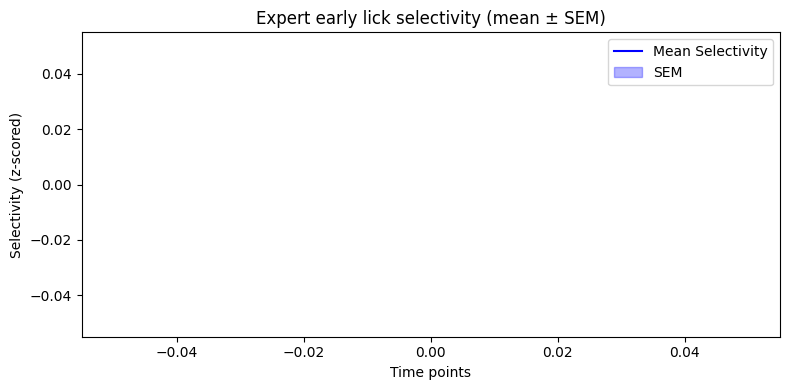

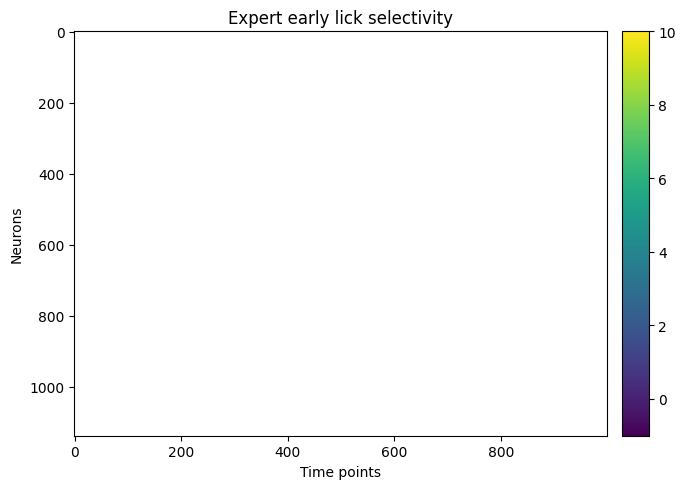

In [154]:

def z_score_normalize(data):
    return (data - np.mean(data)) / np.std(data)
    
# Optionally keep naive_r_pref and learning_r_pref calculation if you want, but only plot expert!
all_sel_traces_delay_EL = z_score_normalize(all_sel_traces_delay_EL)

# Plot selectivity as a line

import scipy.stats as stats

# Compute the mean and SEM across rows (neurons)
mean_trace = np.mean(all_sel_traces_delay_EL, axis=0)
sem_trace = np.std(all_sel_traces_delay_EL, axis=0) / np.sqrt(all_sel_traces_delay_EL.shape[0])

# X axis is time points (columns)
x = np.arange(all_sel_traces_delay_EL.shape[1])

plt.figure(figsize=(8, 4))
plt.plot(x, mean_trace, label='Mean Selectivity', color='blue')
plt.fill_between(x, mean_trace - sem_trace, mean_trace + sem_trace, color='blue', alpha=0.3, label='SEM')
plt.xlabel('Time points')
plt.ylabel('Selectivity (z-scored)')
plt.title('Expert early lick selectivity (mean ± SEM)')
plt.legend()
plt.tight_layout()
plt.show()









# Plot expert_r_pref as a heatmap with all rows shown and aspect ratio optimized for "squareness"
num_rows, num_cols = all_sel_traces_delay_EL.shape
expert_r_pref_display = all_sel_traces_delay_EL #[:, col_start:]

# Make the plot much more "compressed" vertically, stretched in x,
# resembling a ~5x6 rectangle (wider than it is tall)
fig_width, fig_height = 8, 5  # preserve the look of the original
fig, ax = plt.subplots(1, 1, figsize=(fig_width, fig_height))

# vmin/vmax and aspect for single panel
vmin, vmax = -1, 10
cmap = 'viridis'
aspect = 'auto'

# Plot Expert only
im = ax.imshow(
    all_sel_traces_delay_EL,
    cmap=cmap,
    vmin=vmin,
    vmax=vmax,
    aspect=aspect,
    interpolation='nearest'
)
ax.set_title("Expert early lick selectivity")
ax.set_xlabel("Time points")
ax.set_ylabel("Neurons")

# Draw thick vertical black dotted lines at s1.sample, s1.delay, s1.response locations
# event_times = [np.where(time > s1.sample)[0][0], np.where(time > s1.delay)[0][0], np.where(time > s1.response)[0][0]]
# for t in event_times:
#     ax.axvline(t, color='k', linestyle=':', linewidth=1.5, alpha=1.0)

# Move colorbar to the far right, match style
from mpl_toolkits.axes_grid1 import make_axes_locatable
divider = make_axes_locatable(ax)
cax = divider.append_axes("right", size="5%", pad=0.15)
plt.subplots_adjust(right=0.88)  # to make sure the colorbar fits at the side

cbar = fig.colorbar(im, cax=cax, orientation='vertical')
plt.tight_layout(rect=[0, 0, 0.87, 1])  # leave room for colorbar
plt.show()


18 trials removed for stability reasons
only ppyr neurons: 333 --> 299
in house train test sorting
time taken: 75.036630153656
Not enough trials to train
16 trials removed for stability reasons
only ppyr neurons: 299 --> 249
in house train test sorting
time taken: 48.17305397987366
Not enough trials to train
11 trials removed for stability reasons
only ppyr neurons: 225 --> 184
in house train test sorting
time taken: 32.36825776100159
calculation time: 0.1648414134979248


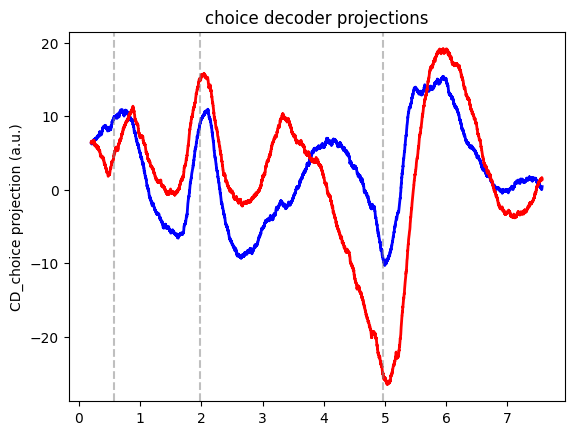

28 trials removed for stability reasons
only ppyr neurons: 270 --> 242
in house train test sorting
time taken: 48.23318004608154
Not enough trials to train
84 trials removed for stability reasons
only ppyr neurons: 268 --> 227
in house train test sorting
time taken: 32.28555870056152
calculation time: 0.2921159267425537


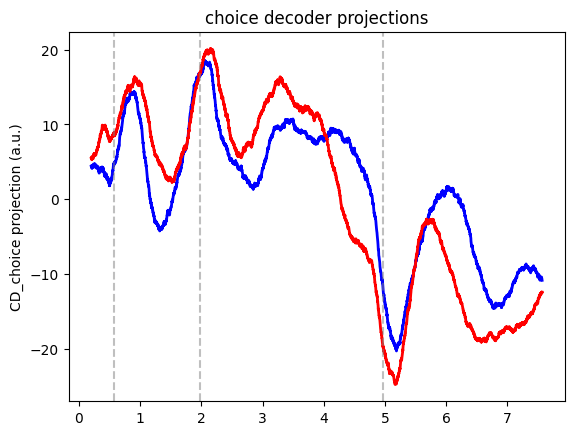

26 trials removed for stability reasons
only ppyr neurons: 241 --> 210
in house train test sorting
time taken: 33.660764932632446
Not enough trials to train
47 trials removed for stability reasons
only ppyr neurons: 295 --> 254
in house train test sorting
time taken: 39.10519289970398
calculation time: 0.32307863235473633


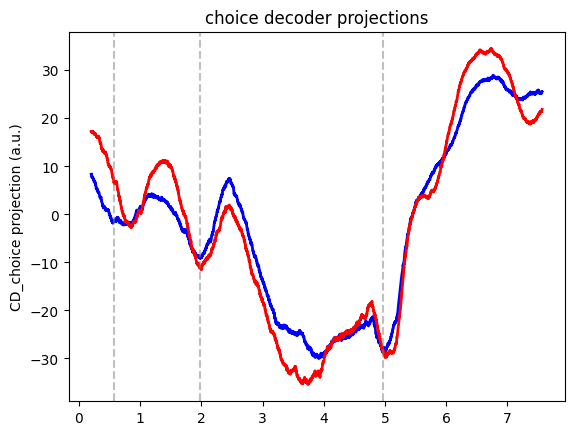

10 trials removed for stability reasons
only ppyr neurons: 295 --> 259
in house train test sorting
time taken: 35.78472852706909
calculation time: 0.3334214687347412


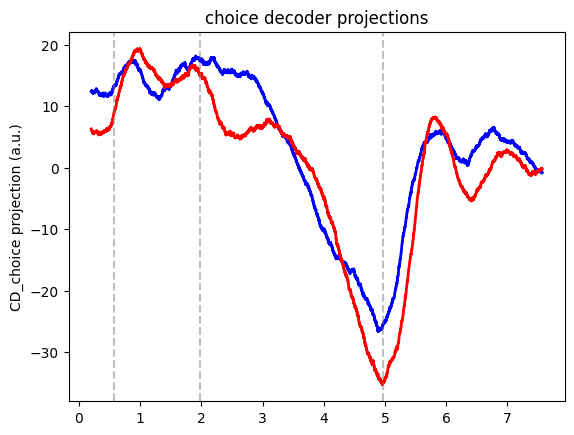

3 trials removed for stability reasons
only ppyr neurons: 310 --> 283
in house train test sorting
time taken: 49.84741234779358
calculation time: 0.37224841117858887


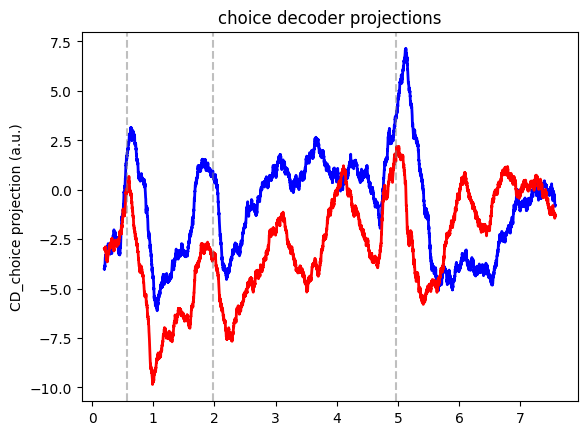

22 trials removed for stability reasons
only ppyr neurons: 422 --> 361
in house train test sorting
time taken: 66.1880874633789
calculation time: 0.4851529598236084


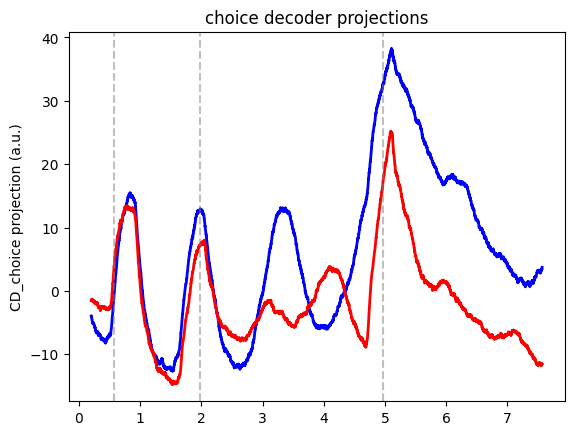

In [139]:
# Naive: take top neurons from CD and plot?
# Trained: plot CD based neurons before early lick


# Expert neurons
p=0.01

all_sel_traces_delay_naive_EL = []

trial_threshold = 2
time_before = 1
binsize=250
timestep=50

for path in naive_paths:

    # s1 = Session(path, passive=False, filter_low_perf=True, filter_by_stim=True)
    # delay_epoch = (s1.delay, s1.response)
    s1 = Mode(path, filter_low_perf=False, filter_by_stim=False)

    # expert_delay_sel, tstat_delay = s1.get_epoch_selective(delay_epoch, p=p, return_stat=True)


    # Get L and R early lick idx and skip if theres not enough trials
    early_lick_trials = np.where(s1.early_lick)[0]
    early_lick_side = [i[0] for i in s1.early_lick_side] # use first lick as direction
    early_lick_time = [i[0][0] for i in s1.early_lick_time]
    # for now keep all the early licks (even in ITI)
    drop_idx = [i for i in range(len(early_lick_time)) if np.abs(0.57-early_lick_time[i]) < 0.2]
    drop_idx = [i for i in range(len(early_lick_time)) if np.abs(1.2-early_lick_time[i]) > 0.2]
    drop_idx = [i for i in range(len(early_lick_time))]
    drop_idx = [i for i in range(len(early_lick_time)) if early_lick_time[i] > time_before+0.57]
    early_lick_trials = np.array(early_lick_trials)[drop_idx]
    early_lick_side = np.array(early_lick_side)[drop_idx]
    early_lick_time = np.array(early_lick_time)[drop_idx]


    early_lick_left, early_lick_right = [],[] #collect idx of el sides
    # for i in range(len(s1.early_lick_side)):
    for i in range(len(early_lick_side)):
        if early_lick_side[i] == 'l':
            early_lick_left += [i]
        else:
            early_lick_right += [i]
    early_lick_left = [i for i in early_lick_left if  early_lick_trials[i] in s1.i_good_non_stim_trials]
    early_lick_right = [i for i in early_lick_right if early_lick_trials[i] in s1.i_good_non_stim_trials]

    if len(early_lick_right) < trial_threshold or len(early_lick_left) < trial_threshold:
        print('Not enough trials to train')
        continue

    cd_choice, _ = s1.plot_CD(mode_input='choice')


    # Delay
    # tstatidx = np.where(np.array(tstat_delay) > 0)[0]
    # l_neurons = np.array(expert_delay_sel)[tstatidx]

    l_neurons = np.array(s1.good_neurons)[np.where(cd_choice[:,0] < 0)]
    r_neurons = np.array(s1.good_neurons)[np.where(cd_choice[:,0] > 0)]
    if len(l_neurons) > 0:

        L_traces_mod = []
        for t in early_lick_left:
            L_traces, time, _ = s1.get_PSTH_multiple(l_neurons, early_lick_trials[t], binsize=binsize, timestep=timestep)
            idx = np.where((time < early_lick_time[t]) & (time > early_lick_time[t] - time_before)) # take the 1.5 seconds before early lick
            L_traces_mod.append(L_traces[:, idx])

        R_traces_mod = []
        for t in early_lick_right:
            R_traces, time, _ = s1.get_PSTH_multiple(l_neurons, early_lick_trials[t], binsize=binsize, timestep=timestep)
            idx = np.where((time < early_lick_time[t]) & (time > early_lick_time[t] - time_before)) # take the 1.5 seconds before early lick
            R_traces_mod.append(R_traces[:, idx])

        all_sel_traces_delay_naive_EL.append(np.mean(L_traces_mod,axis=0)[:,0,:] - np.mean(R_traces_mod,axis=0)[:,0,:])

    # tstatidx = np.where(np.array(tstat_delay) < 0)[0]
    # r_neurons = np.array(expert_delay_sel)[tstatidx]
    if len(r_neurons) > 0:
        
        L_traces_mod = []
        for t in early_lick_left:
            L_traces, time, _ = s1.get_PSTH_multiple(r_neurons, early_lick_trials[t], binsize=binsize, timestep=timestep)
            idx = np.where((time < early_lick_time[t]) & (time > early_lick_time[t] - time_before)) # take the 1.5 seconds before early lick
            L_traces_mod.append(L_traces[:, idx])

        R_traces_mod = []
        counter = 0
        for t in early_lick_right:
            R_traces, time, _ = s1.get_PSTH_multiple(r_neurons, early_lick_trials[t], binsize=binsize, timestep=timestep)
            idx = np.where((time < early_lick_time[t]) & (time > early_lick_time[t] - time_before)) # take the 1.5 seconds before early lick
            R_traces_mod.append(R_traces[:, idx])

        all_sel_traces_delay_naive_EL.append(np.mean(R_traces_mod,axis=0)[:,0,:] - np.mean(L_traces_mod,axis=0)[:,0,:])




In [140]:
all_sel_traces_delay_naive_EL = np.vstack([
    item
    for item in all_sel_traces_delay_naive_EL
    if isinstance(item, (list, np.ndarray)) and len(item) > 0
])

all_sel_traces_delay_naive_EL.shape

(1568, 1000)

In [ ]:

def z_score_normalize(data):
    return (data - np.mean(data)) / np.std(data)
    
# Optionally keep naive_r_pref and learning_r_pref calculation if you want, but only plot expert!
all_sel_traces_delay_naive_EL = z_score_normalize(all_sel_traces_delay_naive_EL)

# Plot selectivity as a line

import scipy.stats as stats

# Compute the mean and SEM across rows (neurons)
mean_trace = np.mean(all_sel_traces_delay_naive_EL, axis=0)
sem_trace = np.std(all_sel_traces_delay_naive_EL, axis=0) / np.sqrt(all_sel_traces_delay_naive_EL.shape[0])

# X axis is time points (columns)
x = np.arange(all_sel_traces_delay_naive_EL.shape[1])

plt.figure(figsize=(8, 4))
plt.plot(x, mean_trace, label='Mean Selectivity', color='blue')
plt.fill_between(x, mean_trace - sem_trace, mean_trace + sem_trace, color='blue', alpha=0.3, label='SEM')
plt.xlabel('Time points')
plt.ylabel('Selectivity (z-scored)')
plt.title('Expert early lick selectivity (mean ± SEM)')
plt.legend()
plt.tight_layout()
plt.show()





# Plot expert_r_pref as a heatmap with all rows shown and aspect ratio optimized for "squareness"
num_rows, num_cols = all_sel_traces_delay_naive_EL.shape
expert_r_pref_display = all_sel_traces_delay_naive_EL #[:, col_start:]

# Make the plot much more "compressed" vertically, stretched in x,
# resembling a ~5x6 rectangle (wider than it is tall)
fig_width, fig_height = 8, 5  # preserve the look of the original
fig, ax = plt.subplots(1, 1, figsize=(fig_width, fig_height))

# vmin/vmax and aspect for single panel
vmin, vmax = -1, 10
cmap = 'viridis'
aspect = 'auto'

# Plot Expert only
im = ax.imshow(
    all_sel_traces_delay_naive_EL,
    cmap=cmap,
    vmin=vmin,
    vmax=vmax,
    aspect=aspect,
    interpolation='nearest'
)
ax.set_title("Expert early lick selectivity")
ax.set_xlabel("Time points")
ax.set_ylabel("Neurons")

# Draw thick vertical black dotted lines at s1.sample, s1.delay, s1.response locations
# event_times = [np.where(time > s1.sample)[0][0], np.where(time > s1.delay)[0][0], np.where(time > s1.response)[0][0]]
# for t in event_times:
#     ax.axvline(t, color='k', linestyle=':', linewidth=1.5, alpha=1.0)

# Move colorbar to the far right, match style
from mpl_toolkits.axes_grid1 import make_axes_locatable
divider = make_axes_locatable(ax)
cax = divider.append_axes("right", size="5%", pad=0.15)
plt.subplots_adjust(right=0.88)  # to make sure the colorbar fits at the side

cbar = fig.colorbar(im, cax=cax, orientation='vertical')
plt.tight_layout(rect=[0, 0, 0.87, 1])  # leave room for colorbar
plt.show()


NameError: name 'all_sel_traces_delay_naive_EL' is not defined

### Plot naive and trained side by side

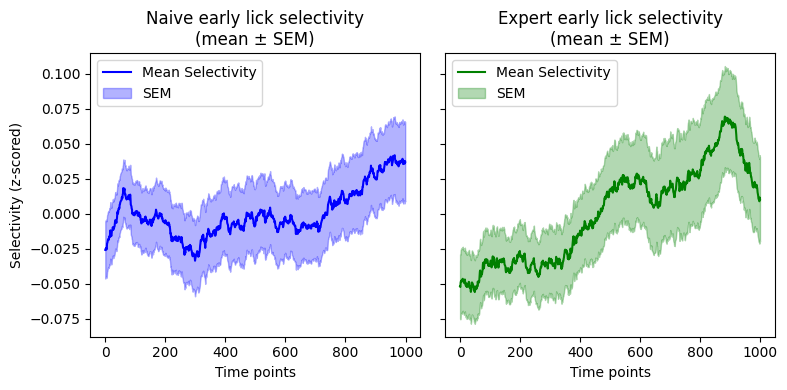

In [145]:
all_sel_traces_delay_naive_EL = z_score_normalize(all_sel_traces_delay_naive_EL)
all_sel_traces_delay_EL = z_score_normalize(all_sel_traces_delay_EL)

# Compute mean and SEM for naive
mean_trace_naive = np.mean(all_sel_traces_delay_naive_EL, axis=0)
sem_trace_naive = np.std(all_sel_traces_delay_naive_EL, axis=0) / np.sqrt(all_sel_traces_delay_naive_EL.shape[0])

# Compute mean and SEM for expert
mean_trace_expert = np.mean(all_sel_traces_delay_EL, axis=0)
sem_trace_expert = np.std(all_sel_traces_delay_EL, axis=0) / np.sqrt(all_sel_traces_delay_EL.shape[0])

# X axis is time points (columns)
x_naive = np.arange(all_sel_traces_delay_naive_EL.shape[1])
x_expert = np.arange(all_sel_traces_delay_EL.shape[1])

fig, axes = plt.subplots(1, 2, figsize=(8, 4), sharey=True)

# Naive
axes[0].plot(x_naive, mean_trace_naive, label='Mean Selectivity', color='blue')
axes[0].fill_between(x_naive, mean_trace_naive - sem_trace_naive, mean_trace_naive + sem_trace_naive, 
                 color='blue', alpha=0.3, label='SEM')
axes[0].set_xlabel('Time points')
axes[0].set_ylabel('Selectivity (z-scored)')
axes[0].set_title('Naive early lick selectivity\n(mean ± SEM)')
axes[0].legend(loc="upper left")

# Expert
axes[1].plot(x_expert, mean_trace_expert, label='Mean Selectivity', color='green')
axes[1].fill_between(x_expert, mean_trace_expert - sem_trace_expert, mean_trace_expert + sem_trace_expert, 
                 color='green', alpha=0.3, label='SEM')
axes[1].set_xlabel('Time points')
axes[1].set_title('Expert early lick selectivity\n(mean ± SEM)')
axes[1].legend(loc="upper left")

plt.tight_layout()
plt.show()




